# [GSE135318](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE135318)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2021-01-15
> - Modified: 2025-01-19

# 1. Experimental Design

> DOT1L-mediated Murine Neuronal Differentiation associates with H3K79me2 Accumulation and preserves SOX2-Enhancer Accessibility.
> - Ferrari, F., Arrigoni, L., Franz, H. et al. DOT1L-mediated murine neuronal differentiation associates with H3K79me2 accumulation and preserves SOX2-enhancer accessibility. Nat Commun 11, 5200 (2020). https://doi.org/10.1038/s41467-020-19001-7.
> - polyA RNA-seq
> - Illumina HiSeq 3000, PE150
> - mm10

| Sample | Organism | Cell | Source | Strand | Genotype | Treatment | Passage |
| - | - | - | - | - | - | - | - |
| mESC DMSO | Mus musculus | mESC | Embryionic stem cells | Dot1l-HA-FLAG C57BL/6 | WT | DMSO | p5 (rep1), p4 (rep2), p7 (rep3) |
| mESC EPZ | Mus musculus | mESC | Embryionic stem cells | Dot1l-HA-FLAG C57BL/6 | WT | Pinometostat (EPZ-5676) | p5 (rep1), p4 (rep2), p7 (rep3) |
| NPC DMSO | Mus musculus | NPC | Neural progenitor cells | Dot1l-HA-FLAG C57BL/6 | WT | DMSO | p5 (rep1), p4 (rep2), p7 (rep3) |
| NPC EPZ | Mus musculus | NPC | Neural progenitor cells | Dot1l-HA-FLAG C57BL/6 | WT | Pinometostat (EPZ-5676) | p5 (rep1), p4 (rep2), p7 (rep3) |

> Notes:
> - DOT1L is a highly conserved histone methyltransferase that catalyzes the mono-, di-, and trimethylation of lysine 79 of histone H3 (H3K79me1/me2/me3). Pinometostat (Synonyms: EPZ-5676) is an S-adenosyl methionine (SAM) competitive inhibitor of histone methyltransferase DOT1L with a Ki of 80 pM. It can inhibit H3K79 methylation.

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [ ]:
data_dir <- "~/dataset_1/bulk_omics/chipseq_Mm_mESC_DOT1L_GSE135318/06_output_rnaseq"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^06_output_rnaseq/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 55335    20

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("rep"))) |>
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        Cell = recode(Cell, "NPC48h" = "NPC"),
        Group = recode(Group, "EPZ5676" = "EPZ"),
        Cell = factor(Cell, levels = c("mESC", "NPC")),
        Group = factor(Group, levels = c("DMSO", "EPZ")), 
        Replicate = factor(Replicate), 
        Passage = rep(c("p5", "p4", "p7"), times = 4) |> factor()) |> 
    arrange(Cell, Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Group,Replicate,Passage
,<fct>,<fct>,<fct>,<fct>
mESC_DMSO_rep1,mESC,DMSO,rep1,p5
mESC_DMSO_rep2,mESC,DMSO,rep2,p4
mESC_DMSO_rep3,mESC,DMSO,rep3,p7
mESC_EPZ5676_rep1,mESC,EPZ,rep1,p5
mESC_EPZ5676_rep2,mESC,EPZ,rep2,p4
mESC_EPZ5676_rep3,mESC,EPZ,rep3,p7
NPC48h_DMSO_rep1,NPC,DMSO,rep1,p5
NPC48h_DMSO_rep2,NPC,DMSO,rep2,p4
NPC48h_DMSO_rep3,NPC,DMSO,rep3,p7


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(12): mESC_DMSO_rep1 mESC_DMSO_rep2 ... NPC48h_EPZ5676_rep2
  NPC48h_EPZ5676_rep3
colData names(4): Cell Group Replicate Passage

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        Cell = recode(Cell, "NPC48h" = "NPC"),
        Group = recode(Group, "EPZ5676" = "EPZ"),
        Cell = factor(Cell, levels = c("mESC", "NPC")),
        Group = factor(Group, levels = c("DMSO", "EPZ")), 
        Replicate = factor(Replicate), 
        Passage = rep(c("p5", "p4", "p7"), times = 4) |> factor()) |> 
    arrange(Cell, Group, Replicate) |>
    select("sampleName", "fileName", "Cell", "Group", "Replicate", "Passage") |>
    as.data.frame()

coldata

sampleName,fileName,Cell,Group,Replicate,Passage
<chr>,<chr>,<fct>,<fct>,<fct>,<fct>
mESC_DMSO_rep1,mESC_DMSO_rep1.tsv,mESC,DMSO,rep1,p5
mESC_DMSO_rep2,mESC_DMSO_rep2.tsv,mESC,DMSO,rep2,p4
mESC_DMSO_rep3,mESC_DMSO_rep3.tsv,mESC,DMSO,rep3,p7
mESC_EPZ5676_rep1,mESC_EPZ5676_rep1.tsv,mESC,EPZ,rep1,p5
mESC_EPZ5676_rep2,mESC_EPZ5676_rep2.tsv,mESC,EPZ,rep2,p4
mESC_EPZ5676_rep3,mESC_EPZ5676_rep3.tsv,mESC,EPZ,rep3,p7
NPC48h_DMSO_rep1,NPC48h_DMSO_rep1.tsv,NPC,DMSO,rep1,p5
NPC48h_DMSO_rep2,NPC48h_DMSO_rep2.tsv,NPC,DMSO,rep2,p4
NPC48h_DMSO_rep3,NPC48h_DMSO_rep3.tsv,NPC,DMSO,rep3,p7


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Group,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): mESC_DMSO_rep1 mESC_DMSO_rep2 ... NPC48h_EPZ5676_rep2
  NPC48h_EPZ5676_rep3
colData names(4): Cell Group Replicate Passage

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        Cell = recode(Cell, "NPC48h" = "NPC"),
        Group = recode(Group, "EPZ5676" = "EPZ"),
        Cell = factor(Cell, levels = c("mESC", "NPC")),
        Group = factor(Group, levels = c("DMSO", "EPZ")), 
        Replicate = factor(Replicate), 
        Passage = rep(c("p5", "p4", "p7"), times = 4) |> factor()) |> 
    arrange(Cell, Group, Replicate) |>
    column_to_rownames("sample")

salmon_quants <- salmon_quants[rownames(coldata)]

coldata

,Cell,Group,Replicate,Passage
,<fct>,<fct>,<fct>,<fct>
mESC_DMSO_rep1,mESC,DMSO,rep1,p5
mESC_DMSO_rep2,mESC,DMSO,rep2,p4
mESC_DMSO_rep3,mESC,DMSO,rep3,p7
mESC_EPZ5676_rep1,mESC,EPZ,rep1,p5
mESC_EPZ5676_rep2,mESC,EPZ,rep2,p4
mESC_EPZ5676_rep3,mESC,EPZ,rep3,p7
NPC48h_DMSO_rep1,NPC,DMSO,rep1,p5
NPC48h_DMSO_rep2,NPC,DMSO,rep2,p4
NPC48h_DMSO_rep3,NPC,DMSO,rep3,p7


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 12 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): mESC_DMSO_rep1 mESC_DMSO_rep2 ... NPC48h_EPZ5676_rep2
  NPC48h_EPZ5676_rep3
colData names(4): Cell Group Replicate Passage

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        Cell = recode(Cell, "NPC48h" = "NPC"),
        Group = recode(Group, "EPZ5676" = "EPZ"),
        Cell = factor(Cell, levels = c("mESC", "NPC")),
        Group = factor(Group, levels = c("DMSO", "EPZ")), 
        Replicate = factor(Replicate), 
        Passage = rep(c("p5", "p4", "p7"), times = 4) |> factor()) |> 
    arrange(Cell, Group, Replicate) |>
    select("names", "files", "Cell", "Group", "Replicate", "Passage") |>
    as.data.frame()

coldata |> dplyr::select(-one_of("files")) |> head()

,names,Cell,Group,Replicate,Passage
,<chr>,<fct>,<fct>,<fct>,<fct>
1,mESC_DMSO_rep1,mESC,DMSO,rep1,p5
2,mESC_DMSO_rep2,mESC,DMSO,rep2,p4
3,mESC_DMSO_rep3,mESC,DMSO,rep3,p7
4,mESC_EPZ5676_rep1,mESC,EPZ,rep1,p5
5,mESC_EPZ5676_rep2,mESC,EPZ,rep2,p4
6,mESC_EPZ5676_rep3,mESC,EPZ,rep3,p7


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-15 08:10:33

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining transcript-to-gene 

In [20]:
DESeqDataSet(gse, design = ~ Group)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 12 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(12): mESC_DMSO_rep1 mESC_DMSO_rep2 ... NPC48h_EPZ5676_rep2
  NPC48h_EPZ5676_rep3
colData names(5): names Cell Group Replicate Passage

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        Cell = recode(Cell, "NPC48h" = "NPC"),
        Group = recode(Group, "EPZ5676" = "EPZ"),
        Cell = factor(Cell, levels = c("mESC", "NPC")),
        Group = factor(Group, levels = c("DMSO", "EPZ")), 
        Replicate = factor(Replicate), 
        Passage = rep(c("p5", "p4", "p7"), times = 4) |> factor()) |> 
    arrange(Cell, Group, Replicate) |>
    column_to_rownames("sample")

kallisto_quants <- kallisto_quants[rownames(coldata)]

coldata |> head()

,Cell,Group,Replicate,Passage
,<fct>,<fct>,<fct>,<fct>
mESC_DMSO_rep1,mESC,DMSO,rep1,p5
mESC_DMSO_rep2,mESC,DMSO,rep2,p4
mESC_DMSO_rep3,mESC,DMSO,rep3,p7
mESC_EPZ5676_rep1,mESC,EPZ,rep1,p5
mESC_EPZ5676_rep2,mESC,EPZ,rep2,p4
mESC_EPZ5676_rep3,mESC,EPZ,rep3,p7


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): mESC_DMSO_rep1 mESC_DMSO_rep2 ... NPC48h_EPZ5676_rep2
  NPC48h_EPZ5676_rep3
colData names(4): Cell Group Replicate Passage

## 2). Object Construction

### a). SummarizedExperiment

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 12 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(12): mESC_DMSO_rep1 mESC_DMSO_rep2 ... NPC48h_EPZ5676_rep2
  NPC48h_EPZ5676_rep3
colData names(4): Cell Group Replicate Passage

### b). DESeqDataSet

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

dds

class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(12): mESC_DMSO_rep1 mESC_DMSO_rep2 ... NPC48h_EPZ5676_rep2
  NPC48h_EPZ5676_rep3
colData names(4): Cell Group Replicate Passage

### c). DGEList

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 23834 
 Remove: 31501 
 Retention rate: 43.07 %


In [29]:
design <- model.matrix(~ group + Cell, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 22842 
 Remove: 32493 
 Retention rate: 41.28 %


# 3. Normalization

| Functional group | Method | Normalizes for sequencing depth? | Normalizes for gene length? | Corrects for RNA composition bias? | Application |
| :-: | :-: | :-: | :-: | :-: | :- |
| **Simple Normalization** | CPM (Counts per million) | Yes | No | No | Gene expression comparison (heatmaps, clustering) |
| | FPKM / RPKM (Fragments/Reads per kilobase per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| | TPM (Transcripts per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| **Statistical Normalization** | TMM (Trimmed mean of M‑values, *edgeR*) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| | Median‑of‑ratios (DESeq2 size factors) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| **Variance stabilization** | VST (Variance stabilizing transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |
| | rlog (Regularized log transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |

> - RNA Composition, a small number of genes account for a large number of reads

## Simple

> Transformation for exploration and visualization

### 1). CPM

> Counts Per Million (CPM) is a widely used method in RNA-seq data analysis to normalize gene expression levels. CPM aims to adjust for differences in sequencing depths across samples and provide relative expression values on a comparable scale by scaling the raw read counts of each gene by a sample-specific sequencing depth (total counts) and multiplying by a scaling factor of one million (to obtain counts per million).
> - Pros:
>    - Relatively simple and intuitive to implement.
>    - Allows for direct comparisons of gene expression levels between samples.
> - Cons:
>    - Does not account for gene length, potentially leading to biases in gene expression estimation.
>    - May be sensitive to extreme values or outliers.

<span style="font-size: 150%">

$$ \text{CPM} = \frac {Count_i} {\sum_{i=1}^{n}(Count_i)} \ *\ 10^6 $$
</span>

In [30]:
cpm <- sweep(assay(eSet), 2, colSums(assay(eSet)), FUN = "/") * 1e6
# cpm <- cpm(dgel, normalized.lib.sizes = FALSE, log = FALSE)
cpm |> head()

,mESC_DMSO_rep1,mESC_DMSO_rep2,mESC_DMSO_rep3,mESC_EPZ5676_rep1,mESC_EPZ5676_rep2,mESC_EPZ5676_rep3,NPC48h_DMSO_rep1,NPC48h_DMSO_rep2,NPC48h_DMSO_rep3,NPC48h_EPZ5676_rep1,NPC48h_EPZ5676_rep2,NPC48h_EPZ5676_rep3
ENSMUSG00000051951.5,0.72840407,0.48774320,1.37541512,0.43857405,0.61738192,1.37585297,34.40056697,17.7300368,21.11885095,25.14038639,18.8255848,27.15662886
ENSMUSG00000102331.1,0.13657576,0.13085793,0.29241109,0.05370295,0.23644414,0.16733347,0.22171329,0.1111988,0.27203944,0.20331894,0.3949423,0.23865678
ENSMUSG00000025902.13,0.59182831,0.54722408,0.44403165,0.58178191,0.48602406,0.40903737,4.94770705,25.5139555,0.94497909,7.18732437,19.4556119,0.77877474
ENSMUSG00000102269.1,0.04552525,0.02379235,0.01083004,0.01790098,0.02627157,0.01859261,0.08168384,0.4447953,0.01431787,0.12199136,0.3479254,0.05024353
ENSMUSG00000098104.1,0.17299597,0.23792351,0.12996048,0.09845540,0.11822207,0.16733347,0.05834560,0.1359097,0.12886079,0.07116163,0.1222441,0.17585236
ENSMUSG00000103922.1,0.35509698,0.38067762,0.22743085,0.33116816,0.30212307,0.27888911,0.33840449,0.1729760,0.20045011,0.26431462,0.4231525,0.33914384


### 2). FPKM/RPKM

> The most basic RNA-Seq normalization method is Reads Per Kilobase of transcript per Million mapped reads (RPKM) or its closely related method, Fragments Per Kilobase of transcript per Million mapped reads (FPKM). These techniques normalize for both the length of the gene and the total number of reads (i.e., the library size), making expression level comparisons between genes in the same sample possible.
> - Pros:
>    - Widely used and established/incorporated in several software tools.
>    - Makes it possible to compare gene expression levels within the same sample and between different samples.
> - Cons:
>    - Assumes that the total number of reads is the same across all samples, which isn't always accurate, particularly when comparing different conditions or tissues.
>    - Can be biased by highly expressed genes or transcripts, making it less reliable for datasets with a high level of expression variation.
>    - It cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{FPKM} = \frac{Count_i}{\left(\frac{Length_i}{10^3}\right) \times \left(\frac{\sum_{i=1}^{n}(Count_i)}{10^6}\right)} = \frac{Count_i}{{Length_i} \times {\sum_{i=1}^{n}(Count_i)}} \times 10^9 $$
</span>

In [31]:
fpkm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs / 1e3, FUN = "/") |>
    sweep(2, colSums(assay(eSet)) / 1e6, FUN = "/")
# fpkm <- fpkm(dds, robust = FALSE)
# fpkm <- rpkm(
#     dgel, gene.length = "basepairs", 
#     normalized.lib.sizes = FALSE)
fpkm |> head()

,mESC_DMSO_rep1,mESC_DMSO_rep2,mESC_DMSO_rep3,mESC_EPZ5676_rep1,mESC_EPZ5676_rep2,mESC_EPZ5676_rep3,NPC48h_DMSO_rep1,NPC48h_DMSO_rep2,NPC48h_DMSO_rep3,NPC48h_EPZ5676_rep1,NPC48h_EPZ5676_rep2,NPC48h_EPZ5676_rep3
ENSMUSG00000051951.5,0.11952807,0.080036626,0.225699888,0.071968174,0.101309799,0.225771737,5.64498966,2.90942515,3.465515417,4.12543262,3.08920000,4.45628961
ENSMUSG00000102331.1,0.04190726,0.040152786,0.089724175,0.016478351,0.072551132,0.051345035,0.06803108,0.03412054,0.083473285,0.06238691,0.12118513,0.07323006
ENSMUSG00000025902.13,0.12402102,0.114673947,0.093049382,0.121915739,0.101849133,0.085716129,1.03682042,5.34659586,0.198025795,1.50614509,4.07703518,0.16319672
ENSMUSG00000102269.1,0.01522075,0.007954648,0.003620876,0.005984949,0.008783541,0.006216184,0.02730988,0.14871125,0.004786983,0.04078615,0.11632410,0.01679824
ENSMUSG00000098104.1,0.11768433,0.161852729,0.088408492,0.066976462,0.080423176,0.113832292,0.03969089,0.09245557,0.087660398,0.04840927,0.08315922,0.11962746
ENSMUSG00000103922.1,0.33217679,0.356106284,0.212751025,0.309792481,0.282622139,0.260887853,0.31656173,0.16181101,0.187511797,0.24725408,0.39583957,0.31725336


### 3). TPM

> Transcripts Per Kilobase Million (TPM) is an improvement over RPKM/FPKM. TPM first normalizes for gene length, then for sequencing depth, making the sum of all TPMs in each sample identical. This allows for a more accurate comparison of gene expression between samples.
> - Pros:
>    - More accurate than RPKM/FPKM for comparing gene expression levels between samples.
>    - Accounts for the total sum of normalized expression levels, allowing for a more balanced comparison.
> - Cons:
>    - Can be affected by highly expressed genes and depends on accurate estimates of gene lengths and accurate read mapping.
>    - Cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{TPM} = \frac{\frac{Count_i} {Length_i}}{\sum_{i=1}^{n}(\frac{Count_i}{Length_i})} \times 10^6 = \frac{FPKM}{\sum_{i=1}^{n}(FPKM)} \times 10^6 $$
</span>

In [32]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
# tpm <- sweep(fpkm, 2, colSums(fpkm), FUN = "/") * 1e6
tpm |> head()

,mESC_DMSO_rep1,mESC_DMSO_rep2,mESC_DMSO_rep3,mESC_EPZ5676_rep1,mESC_EPZ5676_rep2,mESC_EPZ5676_rep3,NPC48h_DMSO_rep1,NPC48h_DMSO_rep2,NPC48h_DMSO_rep3,NPC48h_EPZ5676_rep1,NPC48h_EPZ5676_rep2,NPC48h_EPZ5676_rep3
ENSMUSG00000051951.5,0.32932012,0.21571383,0.64036292,0.19956421,0.28258960,0.64487858,21.8558275,10.8204515,13.18238983,14.6346734,10.3286203,16.99850457
ENSMUSG00000102331.1,0.11546161,0.10821935,0.25456829,0.04569366,0.20237129,0.14665836,0.2633974,0.1268978,0.31752200,0.2213130,0.4051778,0.27933588
ENSMUSG00000025902.13,0.34169895,0.30906795,0.26400267,0.33806636,0.28409399,0.24483355,4.0142799,19.8845401,0.75326551,5.3429406,13.6314089,0.62251344
ENSMUSG00000102269.1,0.04193574,0.02143928,0.01027326,0.01659597,0.02450047,0.01775547,0.1057362,0.5530724,0.01820909,0.1446859,0.3889251,0.06407684
ENSMUSG00000098104.1,0.32424030,0.43622369,0.25083539,0.18572244,0.22432927,0.32514259,0.1536721,0.3438518,0.33344926,0.1717284,0.2780396,0.45631861
ENSMUSG00000103922.1,0.91520340,0.95977372,0.60362399,0.85903933,0.78833516,0.74518180,1.2256388,0.6017918,0.71327156,0.8771160,1.3234743,1.21016207


## Statistical

> Statistical normalization for differential expression analysis

### 1). DESeq2

> DESeq, a normalization method designed for differential gene expression analysis, uses a more robust negative binomial distribution model. It estimates size factors from the geometric mean of each gene's counts across all samples, effectively scaling for library size and accounting for differences in gene expression variability.
> - Pros:
>    - Robust to outliers and can handle large variations in expression levels.
>    - Ideal for datasets with substantial differences in library sizes or where some genes are only expressed in a subset of samples.
> - Cons:
>    - Assumption that **most genes are not differentially expressed** may not hold in certain experimental conditions.
>    - Relies on the assumption of having a sufficient number of samples to accurately estimate dispersion.

**DESeq2-normalized counts: Median of ratios method**

> 1. Calculate the geometric mean of gene 𝑖:

<span style="font-size: 150%">

$$ g_i = \left(\prod_{j=1}^{n} \mathrm{Count}_{ij}\right)^{1/n} = \exp\left(\frac{1}{n}\sum_{j=1}^{n}\ln(\mathrm{Count}_{ij})\right) $$
</span>

> 2. Calculate the gene ratios:

<span style="font-size: 150%">

$$ r_{ij} = \frac{\mathrm{counts}_{ij}}{g_i} \qquad (g_i>0) $$
</span>

> 3. Calculate the size factor for sample 𝑗 (take the median of all gene ratios):

<span style="font-size: 150%">

$$ s_j = \operatorname{median}_{i}\; r_{ij} \qquad (g_i>0) $$
</span>

> 4. Normalize the counts using the size factor:

<span style="font-size: 150%">

$$ \mathrm{counts}^{(\mathrm{norm})}_{ij} = \frac{\mathrm{counts}_{ij}}{s_j} $$
</span>

> - https://hbctraining.github.io/DGE_workshop/lessons/02_DGE_count_normalization.html

In [33]:
dds <- estimateSizeFactors(dds)
# Calculation of count expression matrix adjusted by normalization factor using the DESeq2 method.
norm_count <- counts(dds, normalized = TRUE)
norm_count |> head()

# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)
norm_fpkm |> head()

,mESC_DMSO_rep1,mESC_DMSO_rep2,mESC_DMSO_rep3,mESC_EPZ5676_rep1,mESC_EPZ5676_rep2,mESC_EPZ5676_rep3,NPC48h_DMSO_rep1,NPC48h_DMSO_rep2,NPC48h_DMSO_rep3,NPC48h_EPZ5676_rep1,NPC48h_EPZ5676_rep2,NPC48h_EPZ5676_rep3
ENSMUSG00000051951.5,66.662199,45.875668,127.577296,40.371199,55.942425,125.442204,3081.375890,1480.770211,2021.130892,2172.579546,1526.228092,2549.342007
ENSMUSG00000102331.1,12.499162,12.308106,27.122732,4.943412,21.424759,15.256484,19.859614,9.287061,26.034906,17.570397,32.018771,22.404023
ENSMUSG00000025902.13,54.163037,51.470261,41.186371,53.553631,44.039781,37.293628,443.182964,2130.864449,90.437043,621.113522,1577.305656,73.107865
ENSMUSG00000102269.1,4.166387,2.237837,1.004546,1.647804,2.380529,1.695165,7.316700,37.148242,1.370258,10.542238,28.207013,4.716636
ENSMUSG00000098104.1,15.832272,22.378374,12.054548,9.062922,10.712379,15.256484,5.226214,11.350852,12.332324,6.149639,9.910572,16.508228
ENSMUSG00000103922.1,32.497822,35.805399,21.095458,30.484374,27.376080,25.427474,30.312042,14.446539,19.183615,22.841516,34.305826,31.837296


,mESC_DMSO_rep1,mESC_DMSO_rep2,mESC_DMSO_rep3,mESC_EPZ5676_rep1,mESC_EPZ5676_rep2,mESC_EPZ5676_rep3,NPC48h_DMSO_rep1,NPC48h_DMSO_rep2,NPC48h_DMSO_rep3,NPC48h_EPZ5676_rep1,NPC48h_EPZ5676_rep2,NPC48h_EPZ5676_rep3
ENSMUSG00000051951.5,0.12045472,0.082894664,0.230524757,0.072948409,0.101084710,0.226666769,5.56786708,2.67566568,3.652066014,3.92572493,2.7578054,4.60651279
ENSMUSG00000102331.1,0.04223215,0.041586608,0.091642242,0.016702792,0.072389938,0.051548583,0.06710163,0.03137910,0.087966698,0.05936683,0.1081850,0.07569868
ENSMUSG00000025902.13,0.12498250,0.118768854,0.095038533,0.123576279,0.101622845,0.086055935,1.02265525,4.91702049,0.208685632,1.43323425,3.6396704,0.16869814
ENSMUSG00000102269.1,0.01533875,0.008238701,0.003698281,0.006066466,0.008764026,0.006240827,0.02693677,0.13676296,0.005044669,0.03881173,0.1038454,0.01736451
ENSMUSG00000098104.1,0.11859668,0.167632349,0.090298433,0.067888708,0.080244493,0.114283560,0.03914862,0.08502717,0.092379206,0.04606583,0.0742383,0.12366014
ENSMUSG00000103922.1,0.33475200,0.368822529,0.217299082,0.314011976,0.281994210,0.261922096,0.31223683,0.14881021,0.197605660,0.23528478,0.3533758,0.32794809


### 2). edgeR' TMM

> Trimmed Mean of M-values (TMM) normalization, implemented in edgeR, calculates scaling factors based on a weighted trimmed mean of the log-expression ratios. This method is robust against high-count genes and differences in RNA composition.
> - Pros:
>    - Deals well with datasets containing different RNA compositions.
>    - Suitable for datasets with a few highly expressed genes or when comparing different conditions or tissues.
> - Cons:
>    - Like DESeq, it assumes that most genes are not differentially expressed, which may not always hold.
>    - Susceptible to the influence of extreme expression values or outliers.

**edgeR-normalized counts: Trimmed Mean of M-values (TMM) normalization Method**

> 1. For gene 𝑖, first calculate the M-value (logarithmic fold change) and A-value (average expression) between sample 𝑗 and reference sample 𝑟:

<span style="font-size: 150%">

$$ M_i = \log_2 \left( \frac{\frac{\text{counts}_{ij}}{N_j}}{\frac{\text{counts}_{ir}}{N_r}} \right) $$
$$ A_i = \frac{1}{2} \log_2 \left( \frac{\text{counts}_{ij}}{N_j} \times \frac{\text{counts}_{ir}}{N_r} \right) $$
</span>

> 2. Deradicalize

> 3. Weighted average


<span style="font-size: 150%">

$$ \text{TMM}_j = \exp \left( \frac{\sum_{i \in S} w_i M_i}{\sum_{i \in S} w_i} \right) $$
$$ w_i = \frac{N_j - \frac{\text{counts}_{ij}}{N_j}}{N_j} + \frac{N_r - \frac{\text{counts}_{ir}}{N_r}}{N_r} $$
</span>

> 4. Calculate the normalization factor for sample 𝑗:

<span style="font-size: 150%">

$$ \frac{1}{\text{TMM}_j} $$
</span>

In [34]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(
    dgel, normalized.lib.sizes = TRUE, log = FALSE)
norm_cpm |> head()

# Calculation of rpkm expression matrix adjusted by normalization factor using the TMM method.
norm_fpkm <- rpkm(
    dgel, gene.length = "basepairs",
    normalized.lib.sizes = TRUE)
norm_fpkm |> head()

,mESC_DMSO_rep1,mESC_DMSO_rep2,mESC_DMSO_rep3,mESC_EPZ5676_rep1,mESC_EPZ5676_rep2,mESC_EPZ5676_rep3,NPC48h_DMSO_rep1,NPC48h_DMSO_rep2,NPC48h_DMSO_rep3,NPC48h_EPZ5676_rep1,NPC48h_EPZ5676_rep2,NPC48h_EPZ5676_rep3
ENSMUSG00000051951.5,0.7523123,0.5047530,1.4066588,0.45293286,0.6201657,1.4047011,33.92992806,16.8827159,21.6648193,23.94965741,17.4235352,27.6367719
ENSMUSG00000102331.1,0.1410586,0.1354215,0.2990535,0.05546117,0.2375103,0.1708420,0.21868000,0.1058846,0.2790722,0.19368910,0.3655287,0.2428763
ENSMUSG00000025902.13,0.6112538,0.5663082,0.4541182,0.60082930,0.4882156,0.4176139,4.88001679,24.2946399,0.9694089,6.84690974,18.0066405,0.7925439
ENSMUSG00000098104.1,0.1786742,0.2462210,0.1329126,0.10167880,0.1187551,0.1708420,0.05754737,0.1294145,0.1321921,0.06779119,0.1131398,0.1789615
ENSMUSG00000103922.1,0.3667523,0.3939536,0.2325971,0.34201053,0.3034854,0.2847367,0.33377473,0.1647094,0.2056322,0.25179583,0.3916379,0.3451401
ENSMUSG00000033845.13,128.4573317,168.0827495,91.3442166,135.63952566,166.5870694,102.2489552,67.57211929,52.4717162,44.8718801,65.75744997,45.6823857,42.4777950


,mESC_DMSO_rep1,mESC_DMSO_rep2,mESC_DMSO_rep3,mESC_EPZ5676_rep1,mESC_EPZ5676_rep2,mESC_EPZ5676_rep3,NPC48h_DMSO_rep1,NPC48h_DMSO_rep2,NPC48h_DMSO_rep3,NPC48h_EPZ5676_rep1,NPC48h_EPZ5676_rep2,NPC48h_EPZ5676_rep3
ENSMUSG00000051951.5,0.12345132,0.08282786,0.23082685,0.07432439,0.10176661,0.23050560,5.56775977,2.77038331,3.55510655,3.93003896,2.85912950,4.53507907
ENSMUSG00000102331.1,0.04328277,0.04155310,0.09176234,0.01701785,0.07287827,0.05242161,0.06710034,0.03248991,0.08563125,0.05943207,0.11215978,0.07452481
ENSMUSG00000025902.13,0.12809174,0.11867314,0.09516308,0.12590723,0.10230838,0.08751338,1.02263554,5.09108129,0.20314519,1.43480925,3.77339491,0.16608212
ENSMUSG00000098104.1,0.12154706,0.16749726,0.09041677,0.06916925,0.08078581,0.11621907,0.03914787,0.08803711,0.08992661,0.04611645,0.07696588,0.12174253
ENSMUSG00000103922.1,0.34307976,0.36852532,0.21758385,0.31993501,0.28389650,0.26635801,0.31223081,0.15407804,0.19235939,0.23554334,0.36635912,0.32286256
ENSMUSG00000033845.13,15.13577609,19.80473071,10.76283924,15.98203437,19.62849882,12.04771476,7.96183802,6.18259882,5.28713091,7.74802050,5.38263058,5.00504242


### 3). limma's voom

> Quantile normalization, used in Limma-Voom (mean-variance modeling at the observational level), transforms the data so that the distribution of gene expression is the same across all samples. It’s particularly useful when comparing many samples.
> - Pros:
>    - Reduces technical variation and is suitable for datasets with complex experimental designs.
>    - Can account for unwanted variation due to hidden confounding factors.
> - Cons:
>    - Assumes that the observed differences in gene expression between samples are due to technical factors, which could ignore biological variation.
>    - Does not account for library size or sequencing depth differences.

In [35]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)
norm_v$E |> head()

,mESC_DMSO_rep1,mESC_DMSO_rep2,mESC_DMSO_rep3,mESC_EPZ5676_rep1,mESC_EPZ5676_rep2,mESC_EPZ5676_rep3,NPC48h_DMSO_rep1,NPC48h_DMSO_rep2,NPC48h_DMSO_rep3,NPC48h_EPZ5676_rep1,NPC48h_EPZ5676_rep2,NPC48h_EPZ5676_rep3
ENSMUSG00000051951.5,-0.4016076,-0.9688631,0.4979412,-1.1279841,-0.6740076,0.495129,5.084731,4.077978,4.43777125,4.582225,4.123326,4.7888508
ENSMUSG00000102331.1,-2.7783281,-2.8203406,-1.7150525,-4.0569010,-2.0344098,-2.509737,-2.155632,-3.161432,-1.80381474,-2.332561,-1.434870,-2.0042314
ENSMUSG00000025902.13,-0.6991015,-0.8047437,-1.1213728,-0.7239177,-1.0150445,-1.243457,2.288586,4.602915,-0.03393452,2.776473,4.170806,-0.3238493
ENSMUSG00000098104.1,-2.4471222,-1.9863505,-2.8525560,-3.2337788,-2.9959357,-2.509737,-3.981603,-2.885798,-2.84128945,-3.783223,-3.089373,-2.4316526
ENSMUSG00000103922.1,-1.4287437,-1.3215347,-2.0701475,-1.5285221,-1.6892743,-1.788453,-1.558391,-2.551379,-2.23123596,-1.962193,-1.336466,-1.5082739
ENSMUSG00000033845.13,7.0051982,7.3930807,6.5133289,7.0836830,7.3801897,6.676009,6.078479,5.713630,5.48797581,6.039189,5.513703,5.4088540


## Variance Stabilization

> Transformation for visualization

### 1). rlog

> Regularized-logarithm transformation: the rlog tends to work well on small datasets (n < 30)

In [36]:
rld <- rlog(dds, blind = FALSE)
assay(rld) |> head()

,mESC_DMSO_rep1,mESC_DMSO_rep2,mESC_DMSO_rep3,mESC_EPZ5676_rep1,mESC_EPZ5676_rep2,mESC_EPZ5676_rep3,NPC48h_DMSO_rep1,NPC48h_DMSO_rep2,NPC48h_DMSO_rep3,NPC48h_EPZ5676_rep1,NPC48h_EPZ5676_rep2,NPC48h_EPZ5676_rep3
ENSMUSG00000051951.5,6.963112,6.665324,7.539683,6.562859,6.822840,7.523367,10.941972,10.099908,10.454083,10.537286,10.134255,10.721699
ENSMUSG00000102331.1,3.816434,3.805871,4.516156,3.118247,4.293378,3.988185,4.224258,3.577403,4.474677,4.113611,4.678687,4.334809
ENSMUSG00000025902.13,6.222356,6.177208,5.972463,6.211670,6.035089,5.881656,8.408539,10.223989,6.720211,8.789469,9.869374,6.510757
ENSMUSG00000102269.1,2.208963,1.837972,1.489026,1.665793,1.874207,1.681207,2.633942,4.156994,1.637677,2.946374,3.882993,2.298857
ENSMUSG00000098104.1,3.800766,4.111127,3.566065,3.334565,3.469374,3.768110,2.941703,3.516286,3.584496,3.046824,3.405286,3.835189
ENSMUSG00000103922.1,4.921428,5.014715,4.516579,4.859869,4.757305,4.688082,4.854023,4.187925,4.433666,4.588686,4.974194,4.900760


### 2). VST

> Variance stabilizing transformation: the VST is much faster to compute and is less sensitive to high count outliers than the rlog.

In [37]:
vsd <- vst(dds, blind = FALSE)
assay(vsd) |> head()

,mESC_DMSO_rep1,mESC_DMSO_rep2,mESC_DMSO_rep3,mESC_EPZ5676_rep1,mESC_EPZ5676_rep2,mESC_EPZ5676_rep3,NPC48h_DMSO_rep1,NPC48h_DMSO_rep2,NPC48h_DMSO_rep3,NPC48h_EPZ5676_rep1,NPC48h_EPZ5676_rep2,NPC48h_EPZ5676_rep3
ENSMUSG00000051951.5,6.191412,5.706945,7.066763,5.545539,5.961975,7.043587,11.592428,10.538508,10.985622,11.089543,10.581941,11.319618
ENSMUSG00000102331.1,4.208026,4.192537,5.060280,3.389678,4.786593,4.413903,4.701047,3.920383,5.011968,4.565656,5.259388,4.837578
ENSMUSG00000025902.13,5.920072,5.854236,5.570623,5.905435,5.655111,5.446659,8.812898,11.061658,6.598298,9.293844,10.629233,6.313573
ENSMUSG00000102269.1,3.264640,2.874610,2.503158,2.716809,2.909090,2.730546,3.706749,5.441814,2.631522,4.040268,5.106848,3.354549
ENSMUSG00000098104.1,4.453252,4.836266,4.171705,3.897779,4.055715,4.413903,3.432076,4.112143,4.194511,3.560979,3.981293,4.498057
ENSMUSG00000103922.1,5.277450,5.396268,4.769024,5.199941,5.071299,4.984254,5.193106,4.356576,4.662416,4.859771,5.343624,5.252485


## Summary

In [38]:
suppressPackageStartupMessages(library(vsn))

In [39]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [40]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](CPM+1))) + 
    common_theme
p3 <- meanSdPlot(log2(fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](FPKM+1))) + 
    common_theme
p4 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p5 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p6 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") + 
    common_theme
p7 <- meanSdPlot(log2(norm_count + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2") + 
    common_theme
p8 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM") + 
    common_theme
p9 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


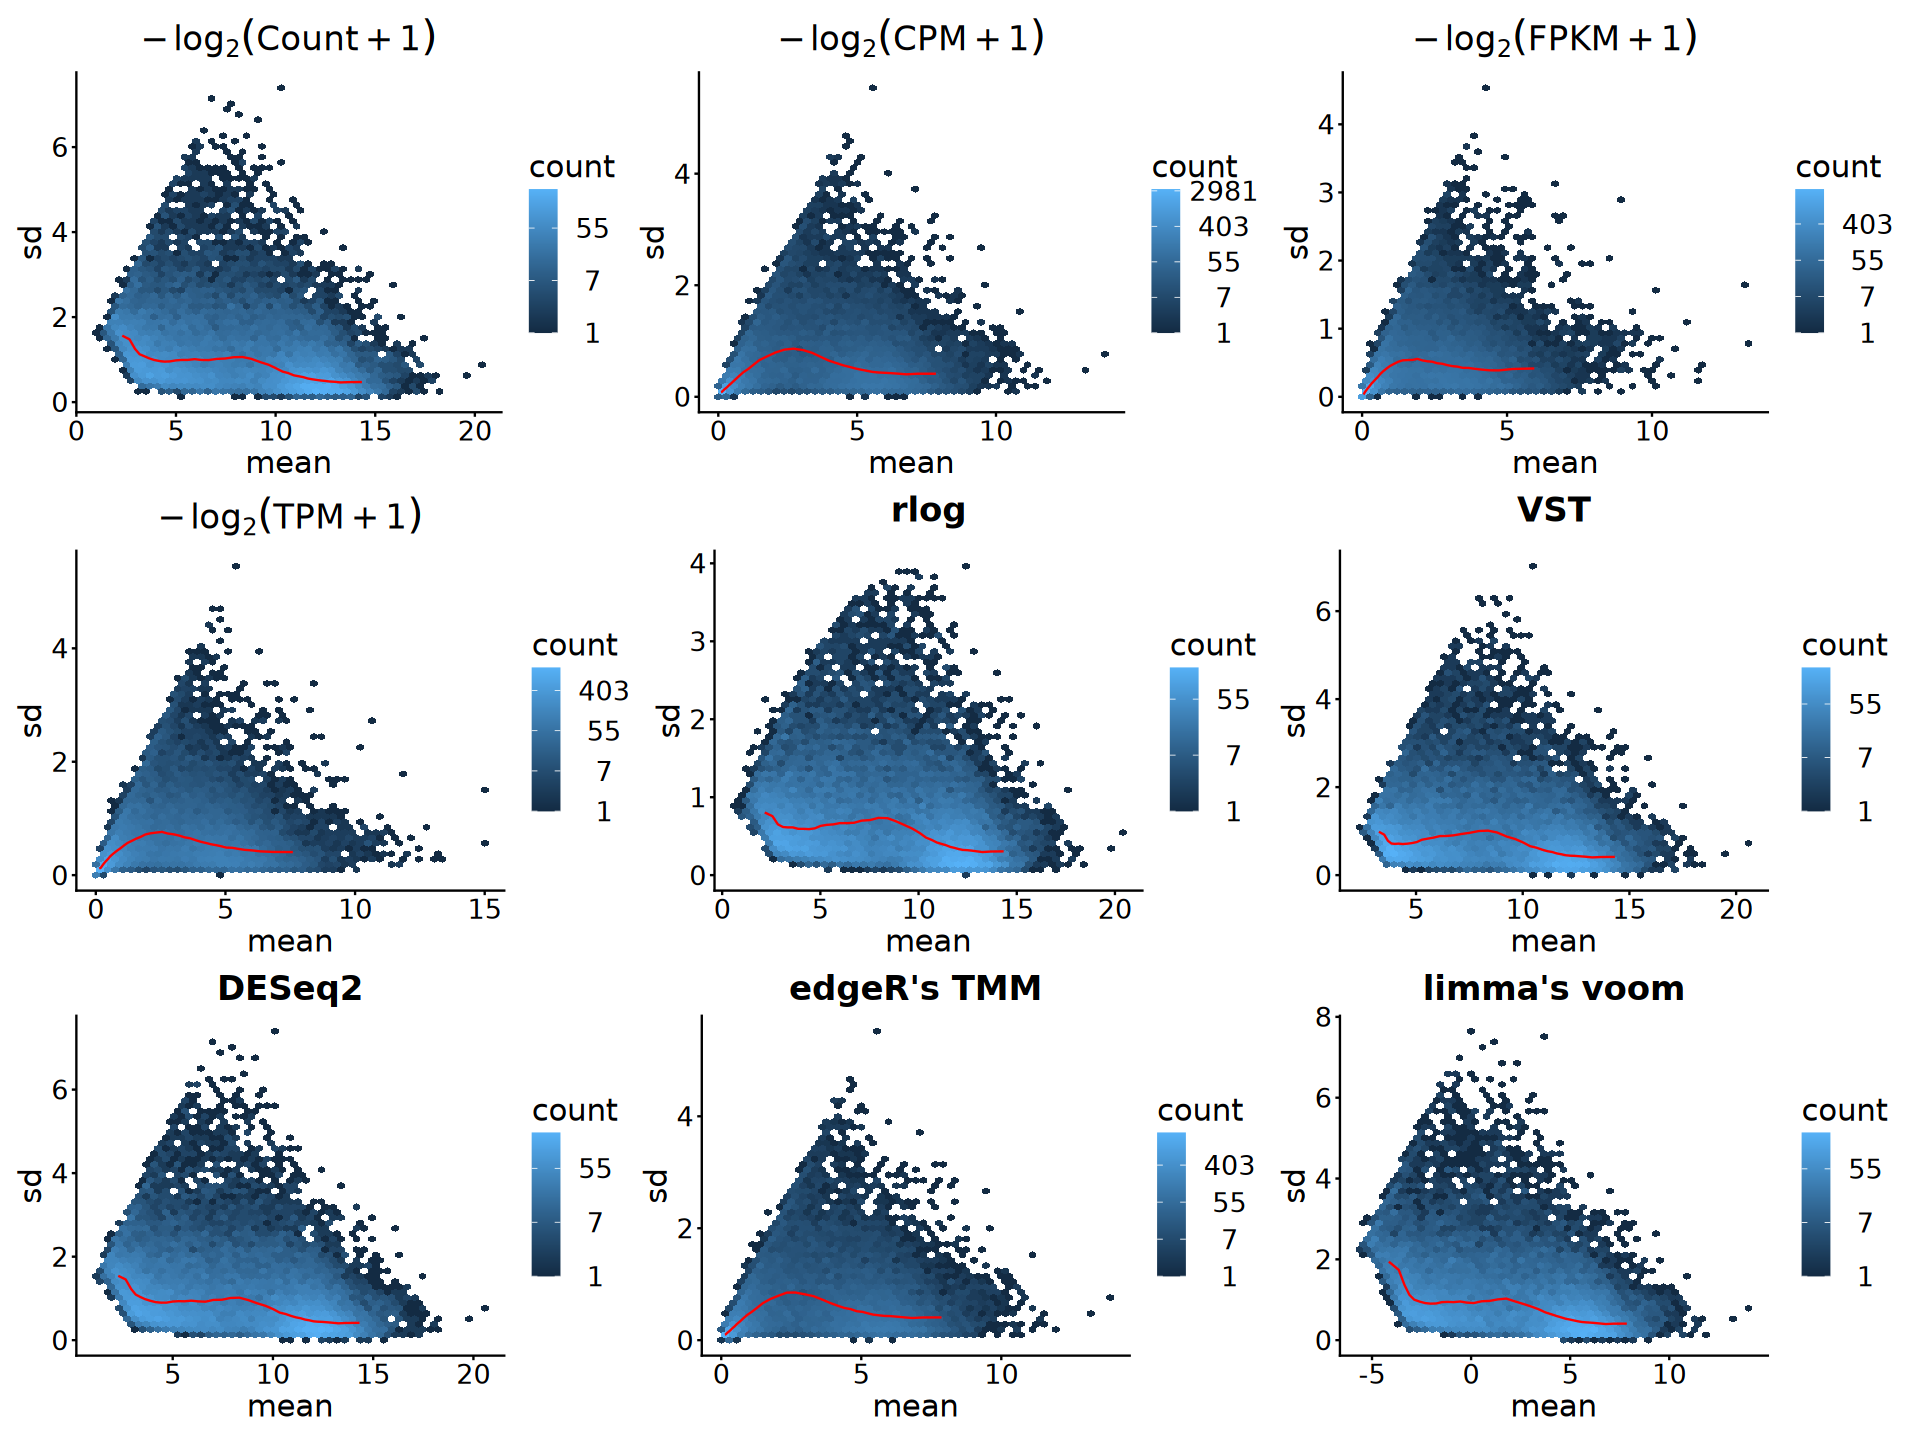

In [41]:
options(repr.plot.width = 16, repr.plot.height = 12)
(p1 + p2 + p3) / (p4 + p5 + p6) / (p7 + p8 + p9)

# 4. Exploration

In [42]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [43]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Cell, Group, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(
        librarySize = colSums(assay(eSet))[Sample], 
        Sample = gsub("_", "\n", Sample), 
        Sample = factor(Sample, levels = Sample))

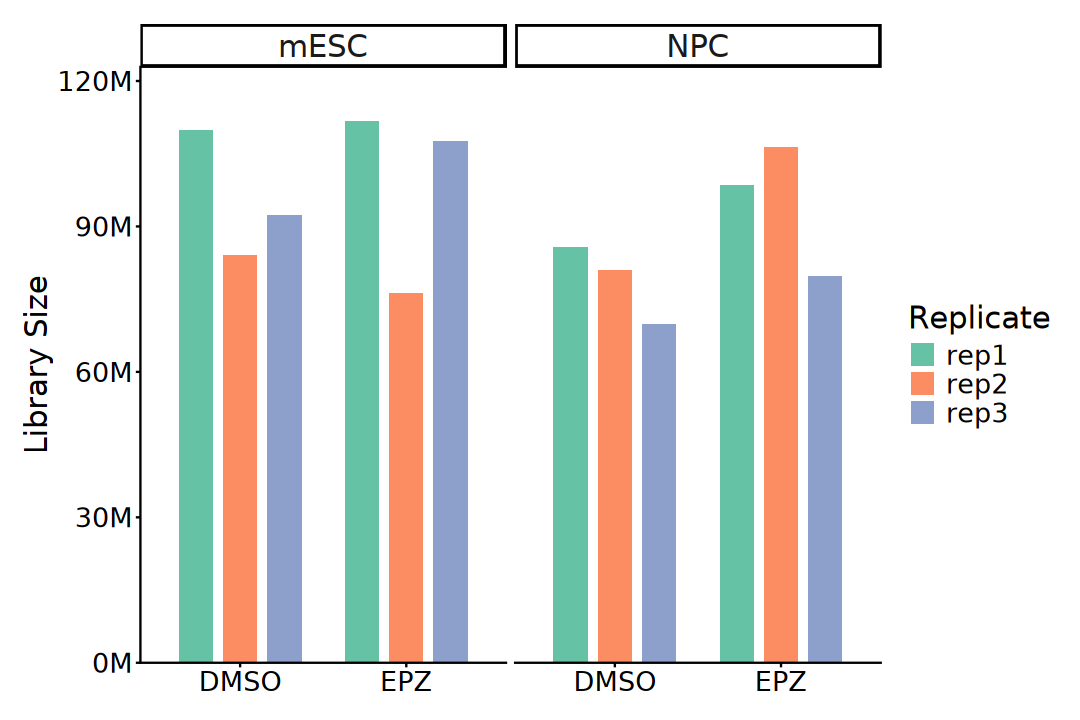

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    facet_wrap(~ Cell, nrow = 1) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [45]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [46]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [47]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [48]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Cell"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [49]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [50]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [51]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

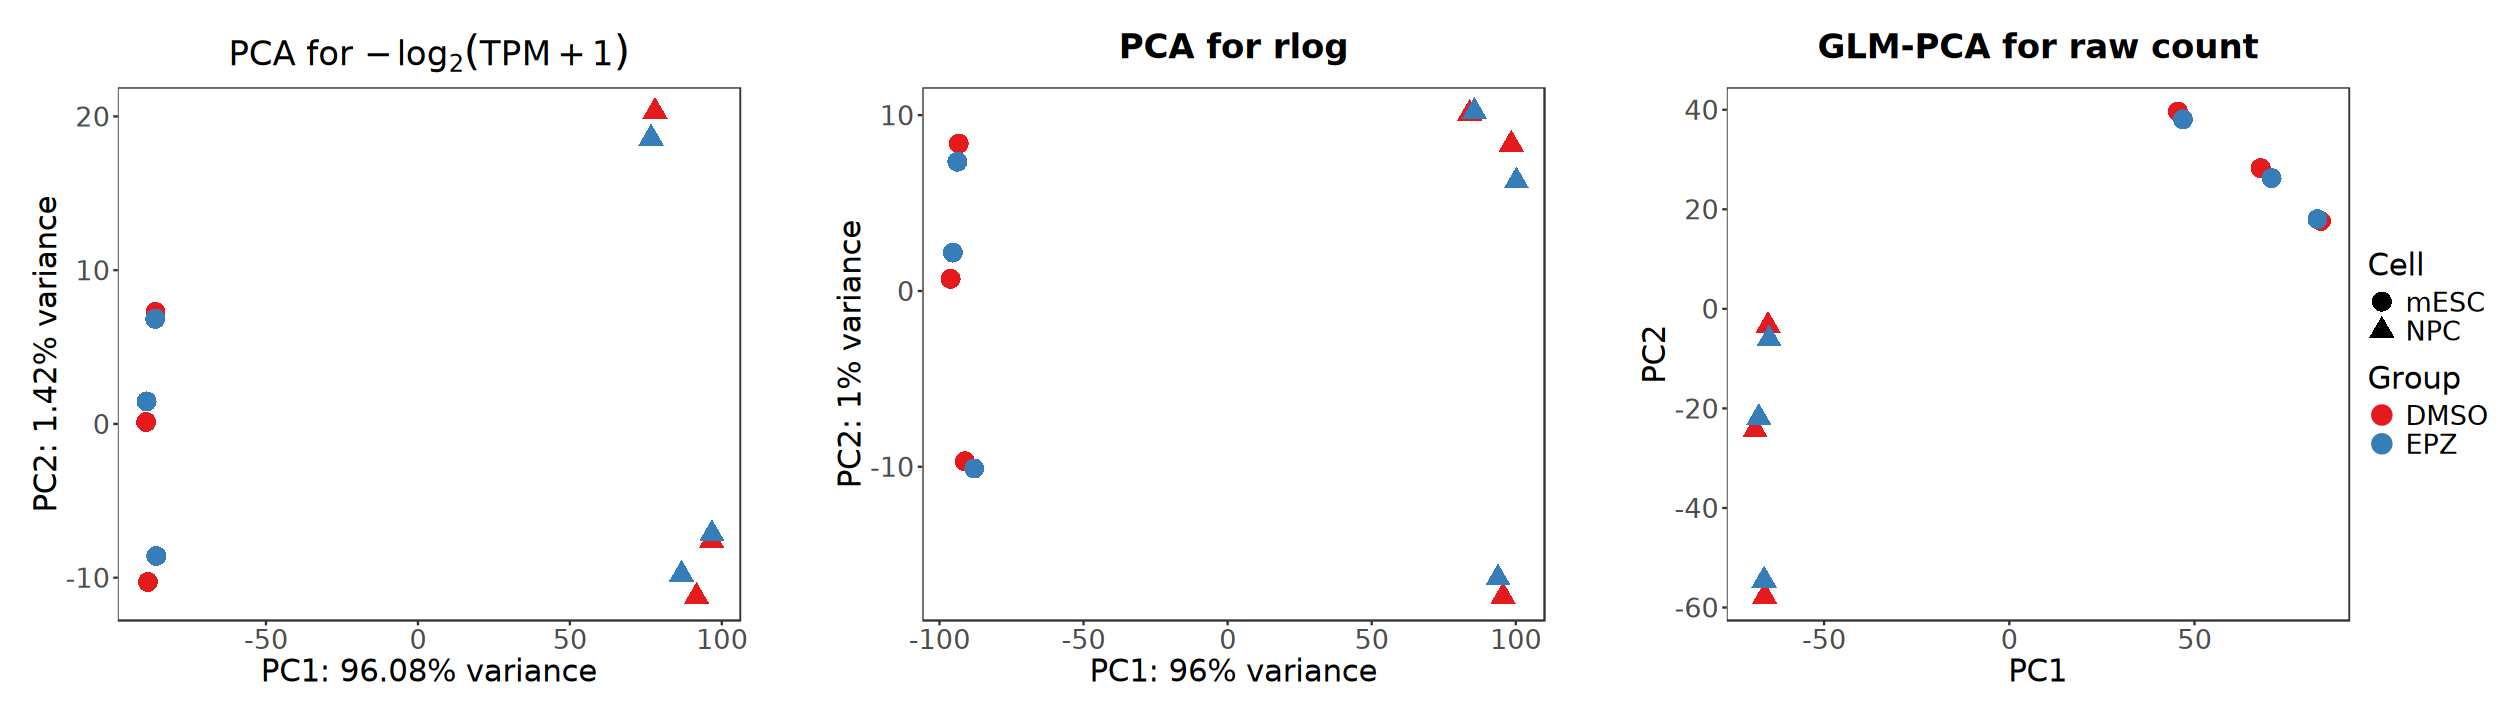

In [52]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [53]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

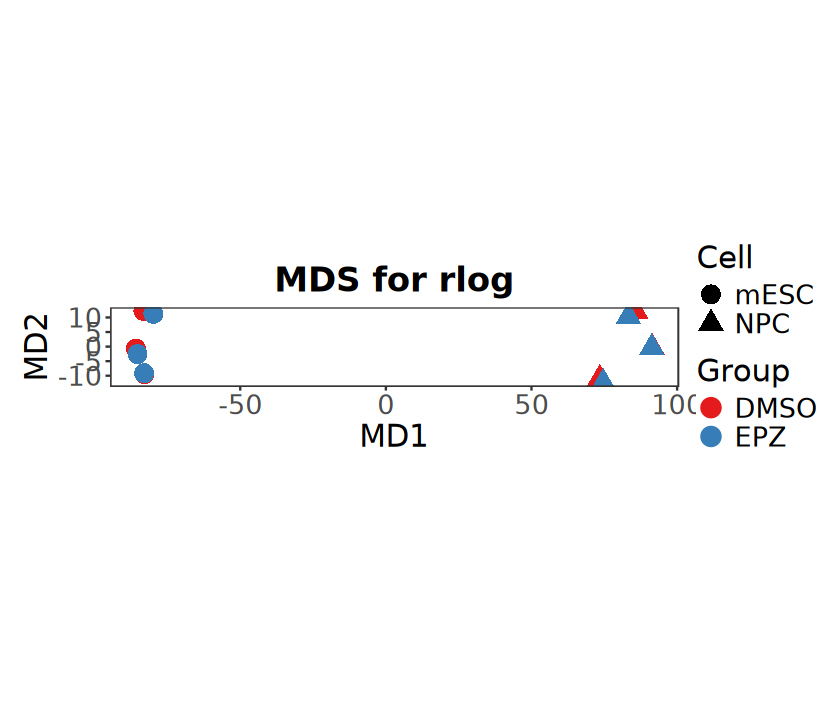

In [54]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [55]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

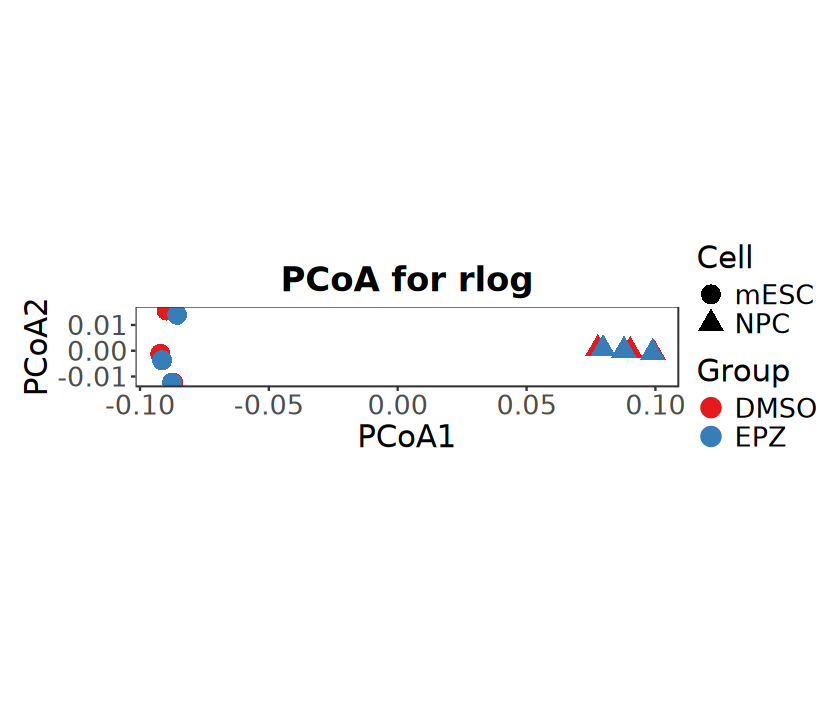

In [56]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [57]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Group, Cell)

In [58]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
cell_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Cell)),
    levels(eSet$Cell))

anno_colors <- list(
    Cell = cell_colors,
    Group = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [59]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

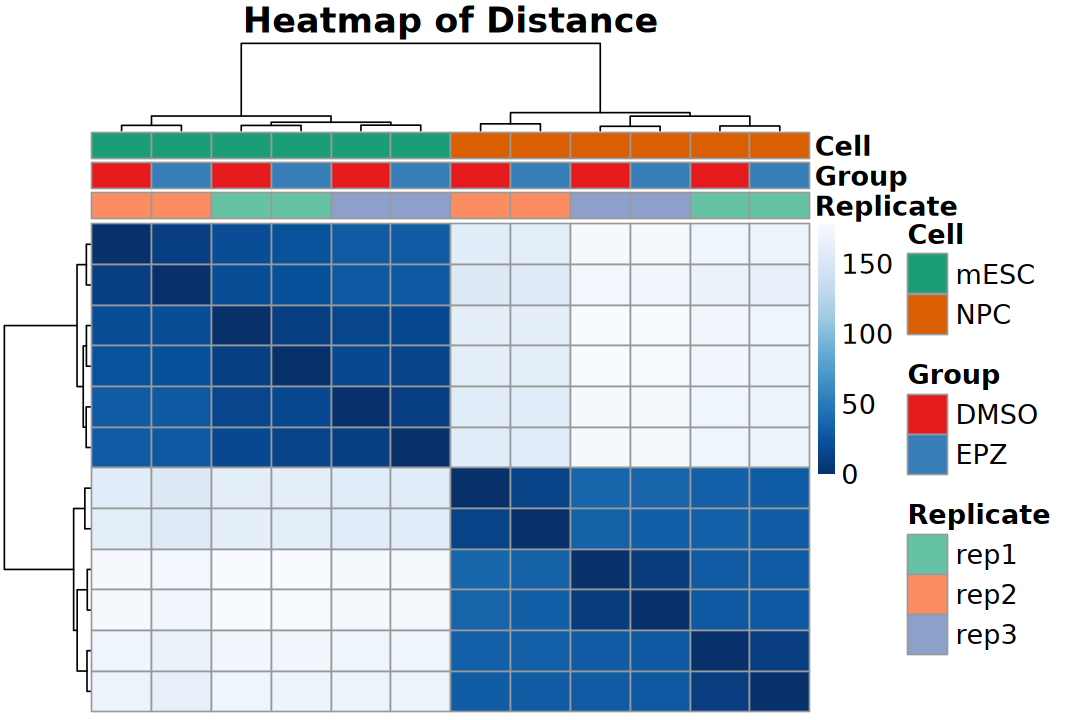

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [61]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

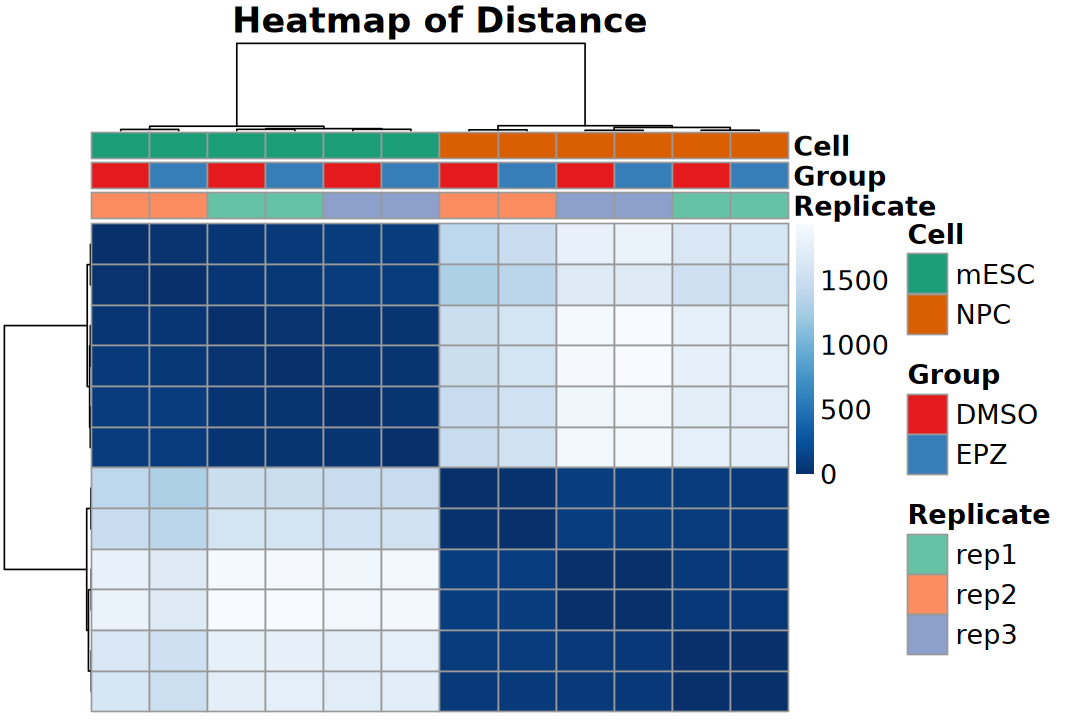

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [63]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

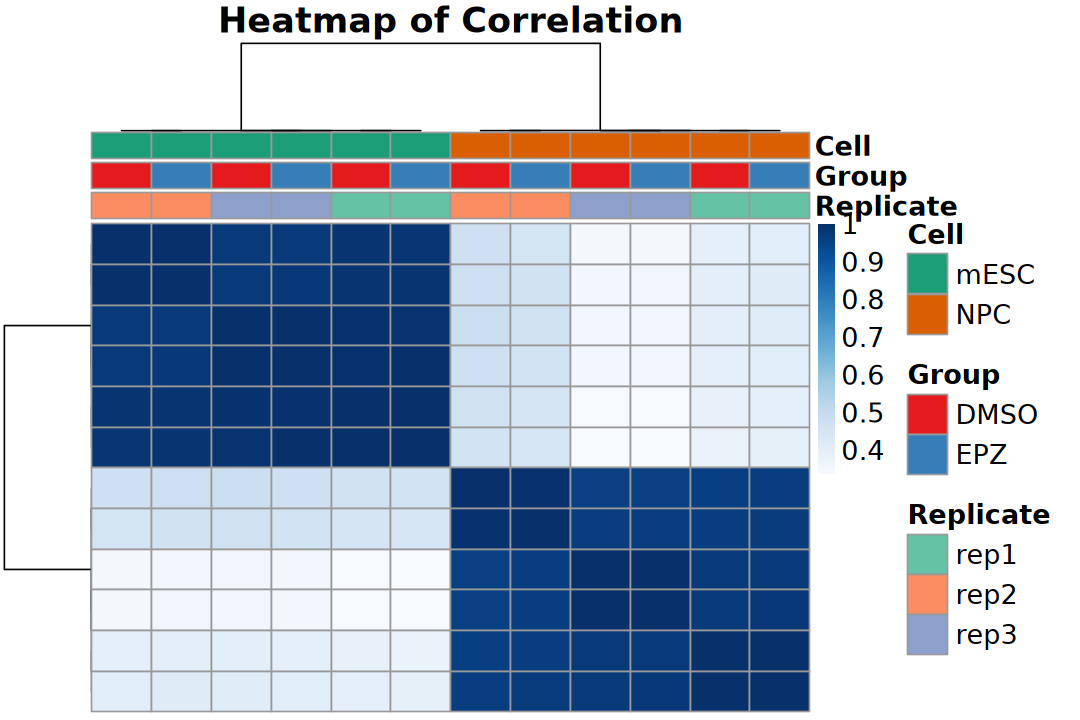

In [64]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

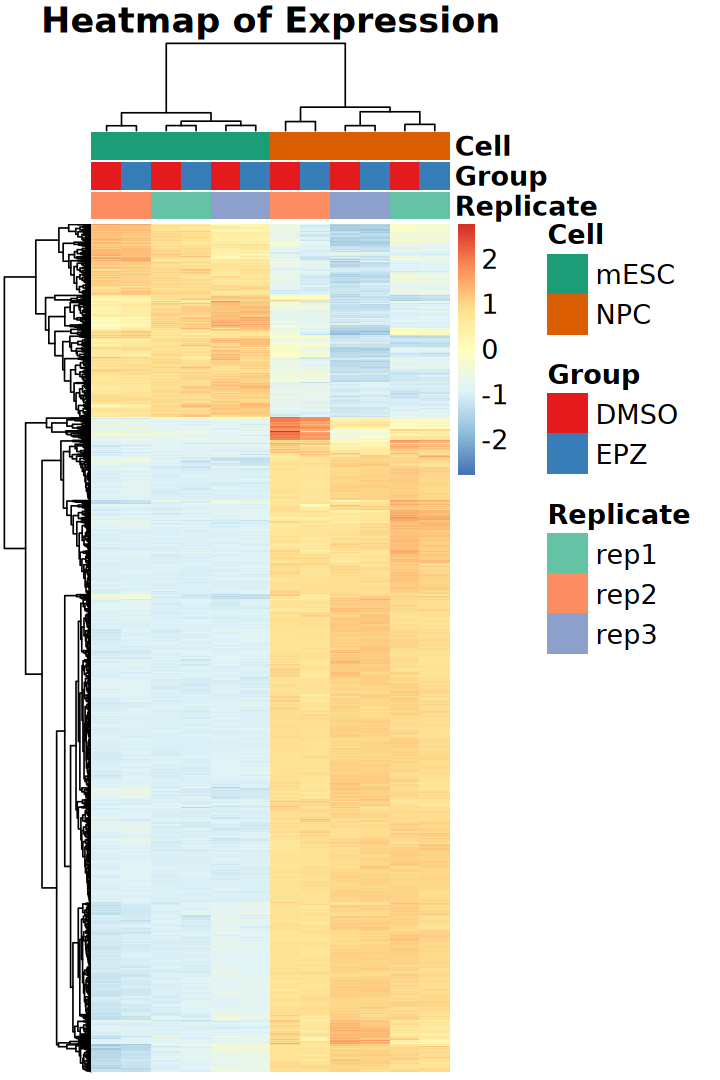

In [65]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [66]:
logfc_cutoff <- log2(1.2)
p_cutoff <- 0.1

## 1). DESeq2

> median of ratios for normalization

In [67]:
design(dds) <- ~ Passage + Cell + Group + Cell:Group
design(dds)

~Passage + Cell + Group + Cell:Group

In [68]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [69]:
resultsNames(dds)

[1] "Intercept"         "Passage_p5_vs_p4"  "Passage_p7_vs_p4" 
[4] "Cell_NPC_vs_mESC"  "Group_EPZ_vs_DMSO" "CellNPC.GroupEPZ"

### a). Standard

In [70]:
# mESCs vs. NPCs under DMSO conditions
results(
    dds, name = "Cell_NPC_vs_mESC", 
    lfcThreshold = logfc_cutoff, alpha = p_cutoff) |> 
    summary()

# mESCs vs. NPCs under EPZ conditions
results(
    dds, contrast = list("Cell_NPC_vs_mESC", "CellNPC.GroupEPZ"),
    lfcThreshold = logfc_cutoff, alpha = p_cutoff) |> 
    summary()


out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0.26 (up)    : 8472, 36%
LFC < -0.26 (down) : 8282, 35%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results


out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0.26 (up)    : 5844, 25%
LFC < -0.26 (down) : 4869, 20%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [71]:
# Effects of EPZ on mESCs
results(
    dds, name = "Group_EPZ_vs_DMSO",
    lfcThreshold = logfc_cutoff, alpha = p_cutoff) |> 
    summary()

# Effects of EPZ on NPCs
results(
    dds, contrast = list("Group_EPZ_vs_DMSO", "CellNPC.GroupEPZ"),
    lfcThreshold = logfc_cutoff, alpha = p_cutoff) |> 
    summary()


out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0.26 (up)    : 1, 0.0042%
LFC < -0.26 (down) : 0, 0%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results


out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0.26 (up)    : 0, 0%
LFC < -0.26 (down) : 0, 0%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [72]:
# Examining whether treatment responses differ between the two cell types
res <- results(
    dds, name = "CellNPC.GroupEPZ",
    lfcThreshold = logfc_cutoff, alpha = p_cutoff)

summary(res)


out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0.26 (up)    : 0, 0%
LFC < -0.26 (down) : 0, 0%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [73]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
    0     0 23834 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,1107.774802,-0.005507942,0.5347721,-0.010299606,0.9927185,0.9999921,NS,Xkr4,protein_coding,6094
ENSMUSG00000102331.1,18.394119,0.752775091,0.8114768,0.927660592,0.3784029,0.9999921,NS,Gm19938,lncRNA,3259
ENSMUSG00000025902.13,434.809851,0.003721814,1.1023009,0.003376405,0.9973816,0.9999921,NS,Sox17,protein_coding,4772
ENSMUSG00000102269.1,8.536113,0.562662624,1.2872311,0.437110799,0.6685847,0.9999921,NS,Gm7357,processed_pseudogene,2991
ENSMUSG00000098104.1,12.231234,0.697693029,0.7246723,0.962770386,0.3667825,0.9999921,NS,Gm6085,processed_pseudogene,1470
ENSMUSG00000103922.1,27.134454,0.579720559,0.5353303,1.082921166,0.3347812,0.9999921,NS,Gm6123,processed_pseudogene,1069


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [74]:
# mESCs vs. NPCs under DMSO conditions
lfcShrink(
    dds, coef = "Cell_NPC_vs_mESC", type = "apeglm") |> 
    summary()

# mESCs vs. NPCs under EPZ conditions
lfcShrink(
    dds, contrast = list("Cell_NPC_vs_mESC", "CellNPC.GroupEPZ"),
    type = "ashr") |> 
    summary()

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 9555, 40%
LFC < 0 (down)     : 9339, 39%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041




out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 6614, 28%
LFC < 0 (down)     : 5612, 24%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [75]:
# Effects of EPZ on mESCs
lfcShrink(
    dds, coef = "Group_EPZ_vs_DMSO", type = "apeglm") |> 
    summary()

# Effects of EPZ on NPCs
lfcShrink(
    dds, contrast = list("Group_EPZ_vs_DMSO", "CellNPC.GroupEPZ"), 
    type = "ashr") |> 
    summary()

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 49, 0.21%
LFC < 0 (down)     : 64, 0.27%
outliers [1]       : 0, 0%
low counts [2]     : 7856, 33%
(mean count < 74)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041




out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 17, 0.071%
LFC < 0 (down)     : 21, 0.088%
outliers [1]       : 0, 0%
low counts [2]     : 6932, 29%
(mean count < 51)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [76]:
# Examining whether treatment responses differ between the two cell types
res_lfc <- lfcShrink(dds, coef = "CellNPC.GroupEPZ", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 4, 0.017%
LFC < 0 (down)     : 6, 0.025%
outliers [1]       : 0, 0%
low counts [2]     : 2773, 12%
(mean count < 13)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [77]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
    4     6 23824 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,1107.774802,-1.007746e-05,0.02405545,0.9917822,0.9999823,NS,Xkr4,protein_coding,6094
ENSMUSG00000102331.1,18.394119,4.710948e-04,0.02407619,0.3535837,0.9999823,NS,Gm19938,lncRNA,3259
ENSMUSG00000025902.13,434.809851,1.141698e-06,0.02407414,0.9973060,0.9999823,NS,Sox17,protein_coding,4772
ENSMUSG00000102269.1,8.536113,1.953051e-04,0.02407693,0.6620310,NA,NS,Gm7357,processed_pseudogene,2991
ENSMUSG00000098104.1,12.231234,7.722391e-04,0.02408502,0.3356628,NA,NS,Gm6085,processed_pseudogene,1470
ENSMUSG00000103922.1,27.134454,1.159300e-03,0.02409734,0.2788434,0.9999823,NS,Gm6123,processed_pseudogene,1069


### Evaluate DEGs

In [78]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [79]:
genes_up <- list(
    raw = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    raw = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [80]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

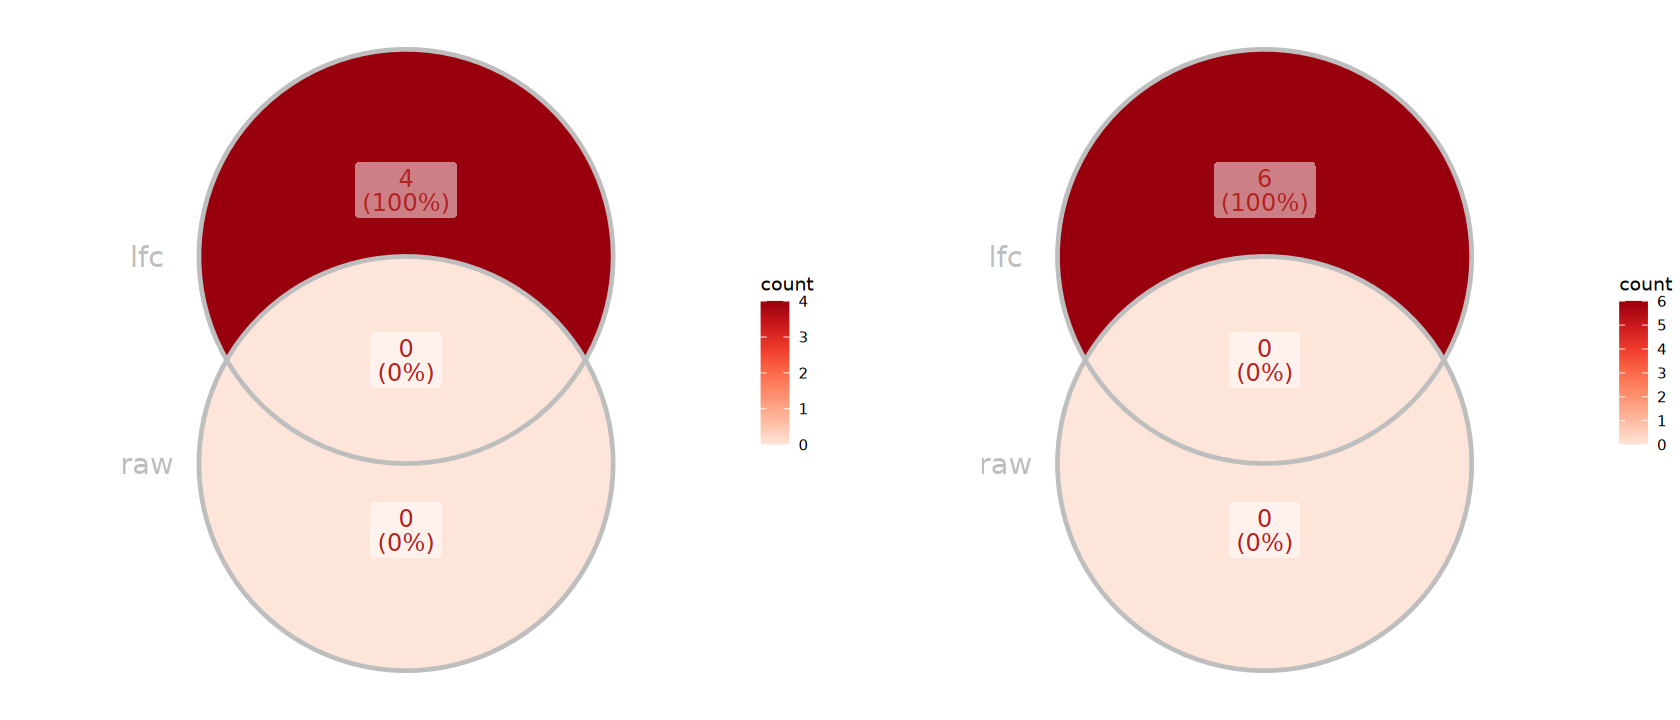

In [81]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). edgeR

> Trimmed Mean of M-values (TMM)

| Pipeline | Advantages | Application | Estimating dispersions | Fitting model | Testing methods | Notes |
| - | - | - | - | - | - | - |
| Classic pipeline (edgeR v1) | - | Single factor design | quantile-adjusted conditional maximum likelihood (qCML) method | Negative binomial model | Exact test (like Fisher’s exact test) | - |
| Negative binomial GLM framework (edgeR v2) | - | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | Negative binomial - Generalized linear model (NB GLM) | Likelihood ratio test (LRT) | - |
| Quasi-likelihood pipeline (edgeR v3) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | - |
| Quasi-likelihood pipeline (edgeR v4) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Estimates a constant NB dispersion based on the most highly expressed genes | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | Default and Recommended approach in edgeR |

### a). Negative binomial GLM framework

In [82]:
design <- model.matrix(~ Passage + Cell*Group, data = dgel$samples)
design

,(Intercept),Passagep5,Passagep7,CellNPC,GroupEPZ,CellNPC:GroupEPZ
mESC_DMSO_rep1,1,1,0,0,0,0
mESC_DMSO_rep2,1,0,0,0,0,0
mESC_DMSO_rep3,1,0,1,0,0,0
mESC_EPZ5676_rep1,1,1,0,0,1,0
mESC_EPZ5676_rep2,1,0,0,0,1,0
mESC_EPZ5676_rep3,1,0,1,0,1,0
NPC48h_DMSO_rep1,1,1,0,1,0,0
NPC48h_DMSO_rep2,1,0,0,1,0,0
NPC48h_DMSO_rep3,1,0,1,1,0,0
NPC48h_EPZ5676_rep1,1,1,0,1,1,1


In [83]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [84]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = "CellNPC:GroupEPZ")

In [85]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)


   Up  Down    NS 
    0     0 22842 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000031285.14,Dcx,protein_coding,12647,-2.196969,9.7439577,20.03159,7.617317e-06,0.1026948,NS
ENSMUSG00000117655.1,6720468P15Rik,lncRNA,2867,2.086903,-1.9430356,19.71448,8.991755e-06,0.1026948,NS
ENSMUSG00000097621.1,Gm26562,lncRNA,2010,1.583523,-0.5523598,18.53745,1.665987e-05,0.1052911,NS
ENSMUSG00000097587.2,4930578M01Rik,lncRNA,6788,-1.578528,1.6412709,18.34418,1.843816e-05,0.1052911,NS
ENSMUSG00000027322.11,Siglec1,protein_coding,7143,4.037906,-1.9800778,17.06530,3.611616e-05,0.1486731,NS
ENSMUSG00000049176.16,Frmpd4,protein_coding,9680,-5.481661,-0.7607074,16.91689,3.905256e-05,0.1486731,NS


### b). Quasi-likelihood pipeline (edgeR v3)

In [86]:
design <- model.matrix(~ Passage + Cell*Group, data = dgel$samples)

In [87]:
dgel_nbglm <- estimateDisp(dgel, design)

In [88]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = "CellNPC:GroupEPZ")

In [89]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)


   Up  Down    NS 
    0     0 22842 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000027270.14,Lamp5,protein_coding,2933,-4.7670781,4.8092679,42.12102,0.0001061663,1,NS
ENSMUSG00000067786.16,Nnat,protein_coding,1829,0.5813694,9.0901771,36.86837,0.0002093930,1,NS
ENSMUSG00000031285.14,Dcx,protein_coding,12647,-2.1968842,9.7439577,30.94490,0.0003580683,1,NS
ENSMUSG00000097587.2,4930578M01Rik,lncRNA,6788,-1.5798822,1.6412709,28.17855,0.0005395942,1,NS
ENSMUSG00000040339.10,Fam102b,protein_coding,5702,-0.7218017,4.8960491,27.57374,0.0005807399,1,NS
ENSMUSG00000097621.1,Gm26562,lncRNA,2010,1.5836013,-0.5523598,26.94711,0.0006317005,1,NS


## 3). limma-voom

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [90]:
design <- model.matrix(~ Passage + Cell*Group, data = dgel$samples)
colnames(design)

[1] "(Intercept)"      "Passagep5"        "Passagep7"        "CellNPC"         
[5] "GroupEPZ"         "CellNPC:GroupEPZ"

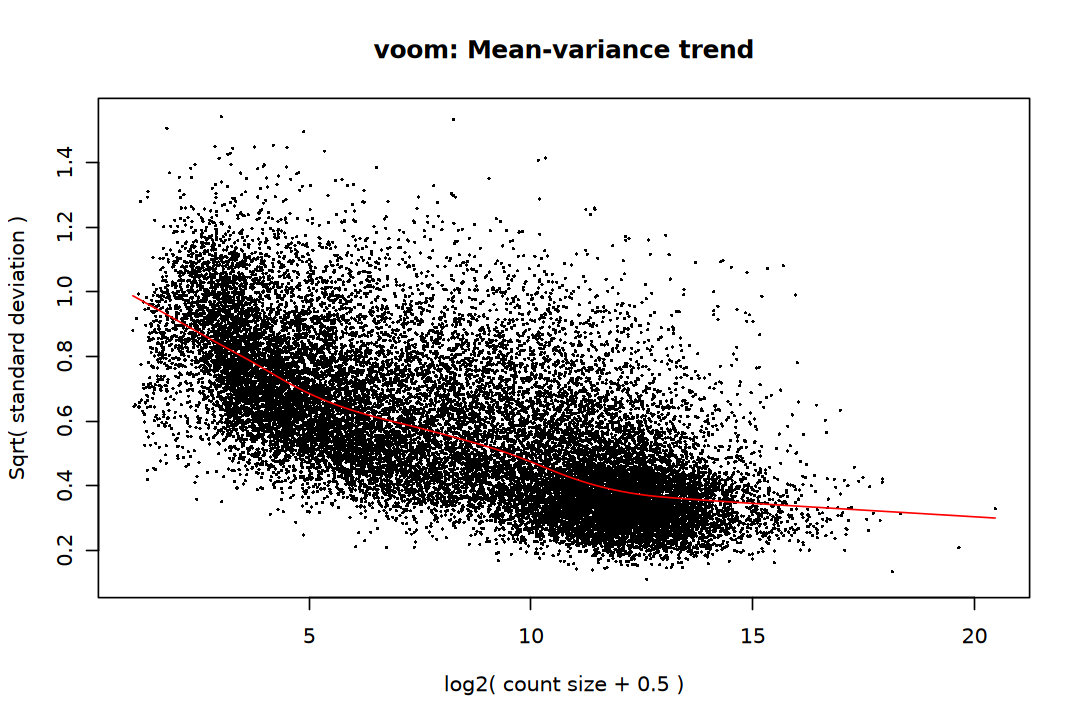

In [91]:
options(repr.plot.width = 9, repr.plot.height = 6)
norm_v <- voom(dgel, design, plot = TRUE)

In [92]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [93]:
limma_voom_result <- topTable(efit, coef = "CellNPC:GroupEPZ", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)


   Up  Down    NS 
    0     0 22842 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000064351.1,mt-Co1,protein_coding,1545,0.4704770,13.958656,4.079179,0.0028700715,0.9999537,-2.788321,NS
ENSMUSG00000013415.9,Igf2bp1,protein_coding,9682,-0.5155793,7.713036,-5.301810,0.0005237220,0.9999537,-3.047034,NS
ENSMUSG00000067786.16,Nnat,protein_coding,1829,0.5773806,7.505306,5.475386,0.0004185753,0.9999537,-3.217545,NS
ENSMUSG00000064370.1,mt-Cytb,protein_coding,1144,0.3830812,11.827128,3.523696,0.0066672450,0.9999537,-3.217731,NS
ENSMUSG00000024758.15,Rtn3,protein_coding,5022,0.2785259,8.620635,3.721576,0.0049149674,0.9999537,-3.386627,NS
ENSMUSG00000026576.12,Atp1b1,protein_coding,3081,0.3905228,7.240432,3.969391,0.0033791658,0.9999537,-3.419295,NS


## DEGs Evaluation

In [94]:
add_label <- function(res, symbol_col = "symbol"){
    res |>
        tibble::rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            label = dplyr::if_else(
                result %in% c("Up", "Down") & dplyr::row_number() <= 10,
                .data[[symbol_col]], NA_character_)) |>
        dplyr::ungroup() |>
        tibble::column_to_rownames("gene_id")
}

In [95]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")

### P-value Histogram

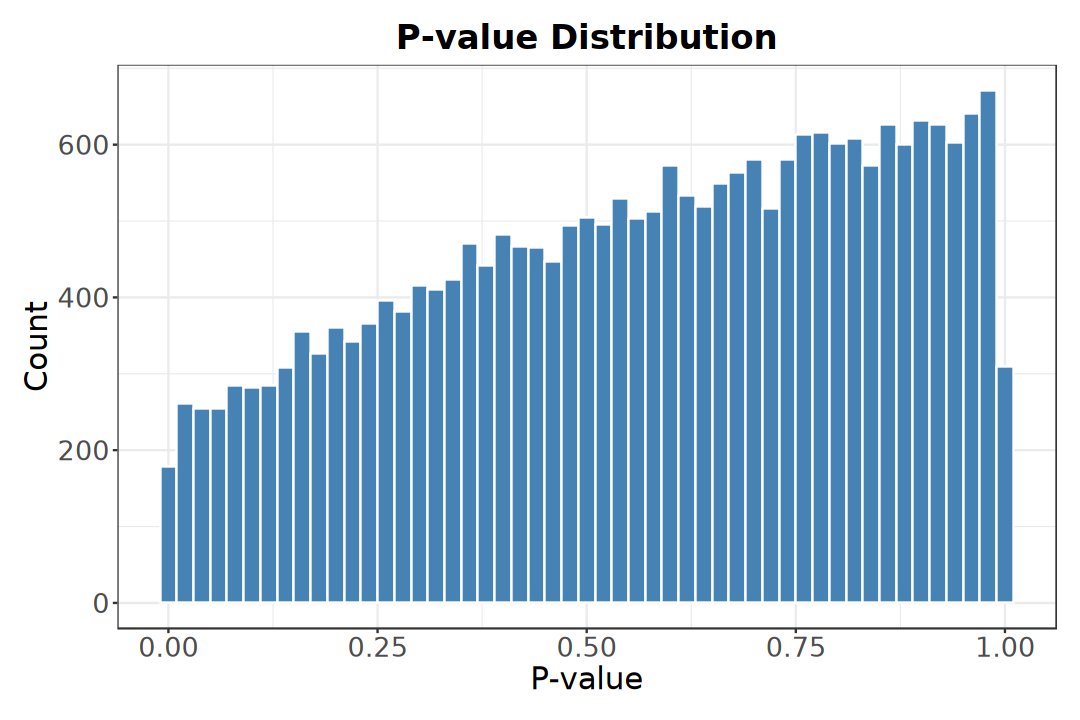

In [96]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deseq2_result, aes(x = pvalue)) +
    geom_histogram(binwidth = 0.02, fill = "steelblue", color = "white") +
    labs(
        title = "P-value Distribution", 
        x = "P-value", y = "Count") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## DEGs Visualization

In [97]:
# Examining whether treatment responses differ between the two cell types
res_lfc <- lfcShrink(dds, coef = "CellNPC.GroupEPZ", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 23834 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 4, 0.017%
LFC < 0 (down)     : 6, 0.025%
outliers [1]       : 0, 0%
low counts [2]     : 2773, 12%
(mean count < 13)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [98]:
degs_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    group_by(result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    column_to_rownames("gene_id")

table(degs_result$result)
head(degs_result)


   Up  Down    NS 
    4     6 23824 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,label
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<chr>
ENSMUSG00000097587.2,282.5691,-1.4256257,0.3454329,1.316495e-06,0.009433991,Down,4930578M01Rik,lncRNA,6788,NA
ENSMUSG00000067736.2,634.5696,0.6933013,0.1694146,1.687555e-06,0.009433991,Up,Gm10222,unprocessed_pseudogene,294,NA
ENSMUSG00000067786.16,49483.4227,0.5258685,0.1289958,1.791746e-06,0.009433991,Up,Nnat,protein_coding,1829,Nnat
ENSMUSG00000013415.9,21085.0728,-0.4631358,0.1131638,1.689833e-06,0.009433991,Down,Igf2bp1,protein_coding,9682,Igf2bp1
ENSMUSG00000040596.15,8141.7714,-0.5685710,0.1399971,2.305687e-06,0.009712013,Down,Pogk,protein_coding,9586,Pogk
ENSMUSG00000048078.16,2816.7177,0.6283950,0.1736371,1.083051e-05,0.038016909,Up,Tenm4,protein_coding,21021,Tenm4


In [99]:
max_logfc <- degs_result$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- degs_result$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### MA plot

> - Mean-Difference plot
> - Bland-Altman plot

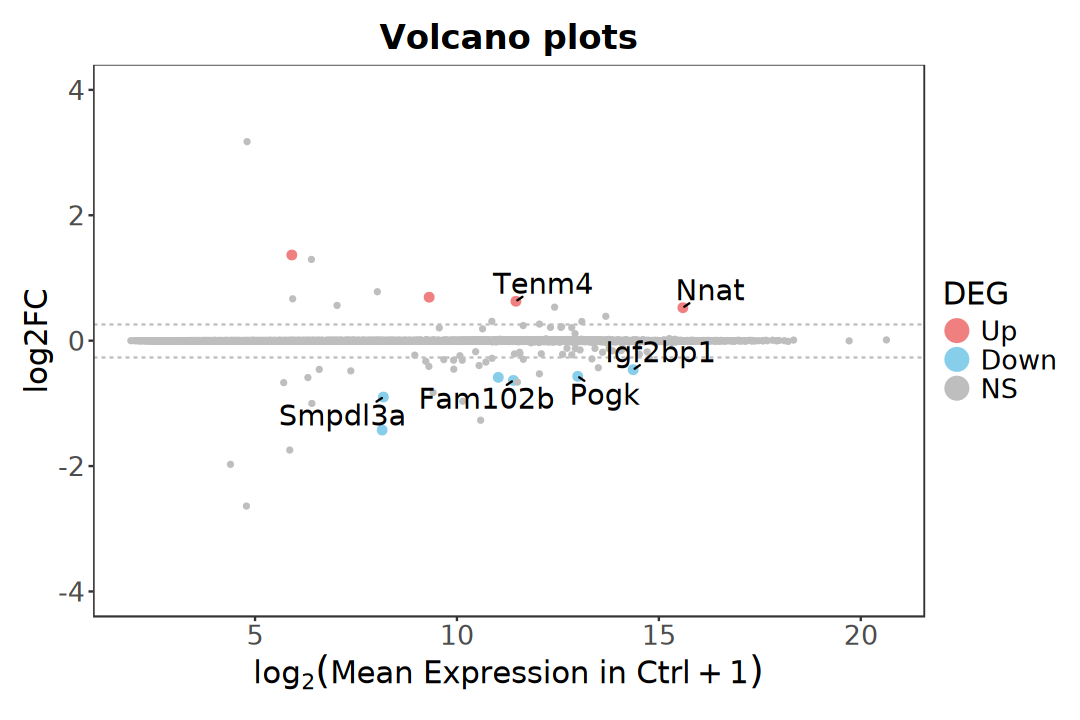

In [100]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(degs_result, aes(x = log2(baseMean + 1), y = logFC)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = "log2FC") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Volcano

In [101]:
p1 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_manual(
        values = c(
            Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(
            Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [102]:
p2 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = logFC, size = logFC), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_gradientn(
        colours = brewer.pal(11, 'RdYlBu') |> rev(), 
        limits = c(-max_logfc, max_logfc)) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [103]:
p3 <- degs_result |>
    mutate(
        neglog10_padj = -log10(pmax(padj, 1e-300)), 
        neglog10_padj_m = ifelse(
            logFC < 0, -neglog10_padj, neglog10_padj)) |>
    ggplot(aes(x = logFC, y = neglog10_padj)) +
        geom_point(
            aes(color = neglog10_padj_m, size = neglog10_padj), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_gradientn(
            name = expression(-log[10](P.adjust)),
            colours = brewer.pal(11, 'RdBu') |> rev(), 
            limits = c(-min_padj, min_padj),
            breaks = c(-min_padj, 0, min_padj),
            labels = c(min_padj, 0, min_padj)) +
        scale_size_continuous(range = c(1, 3), guide = "none") +
        labs(
            title = "Volcano plots", color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            legend.key.size = unit(1, "cm"),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

In [104]:
p4 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = -log10(pmax(padj, 1e-300)), size = -log10(pmax(padj, 1e-300))),
        na.rm = TRUE, alpha = 0.8) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) +  
    # scale_color_viridis_c(
    #     option = "turbo", begin = 0.1, end = 0.9) + 
    # scale_color_gradientn(
    #     colours = brewer.pal(11, 'RdYlBu') |> rev())+
    # scale_color_gradientn(
    #     colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    scale_color_gradientn(
        colors = c(
            "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
            "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
            "#F46D43", "#D53E4F", "#9C2007", "#9E0142")) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots", 
        color = expression(-log[10](P.adjust)),
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

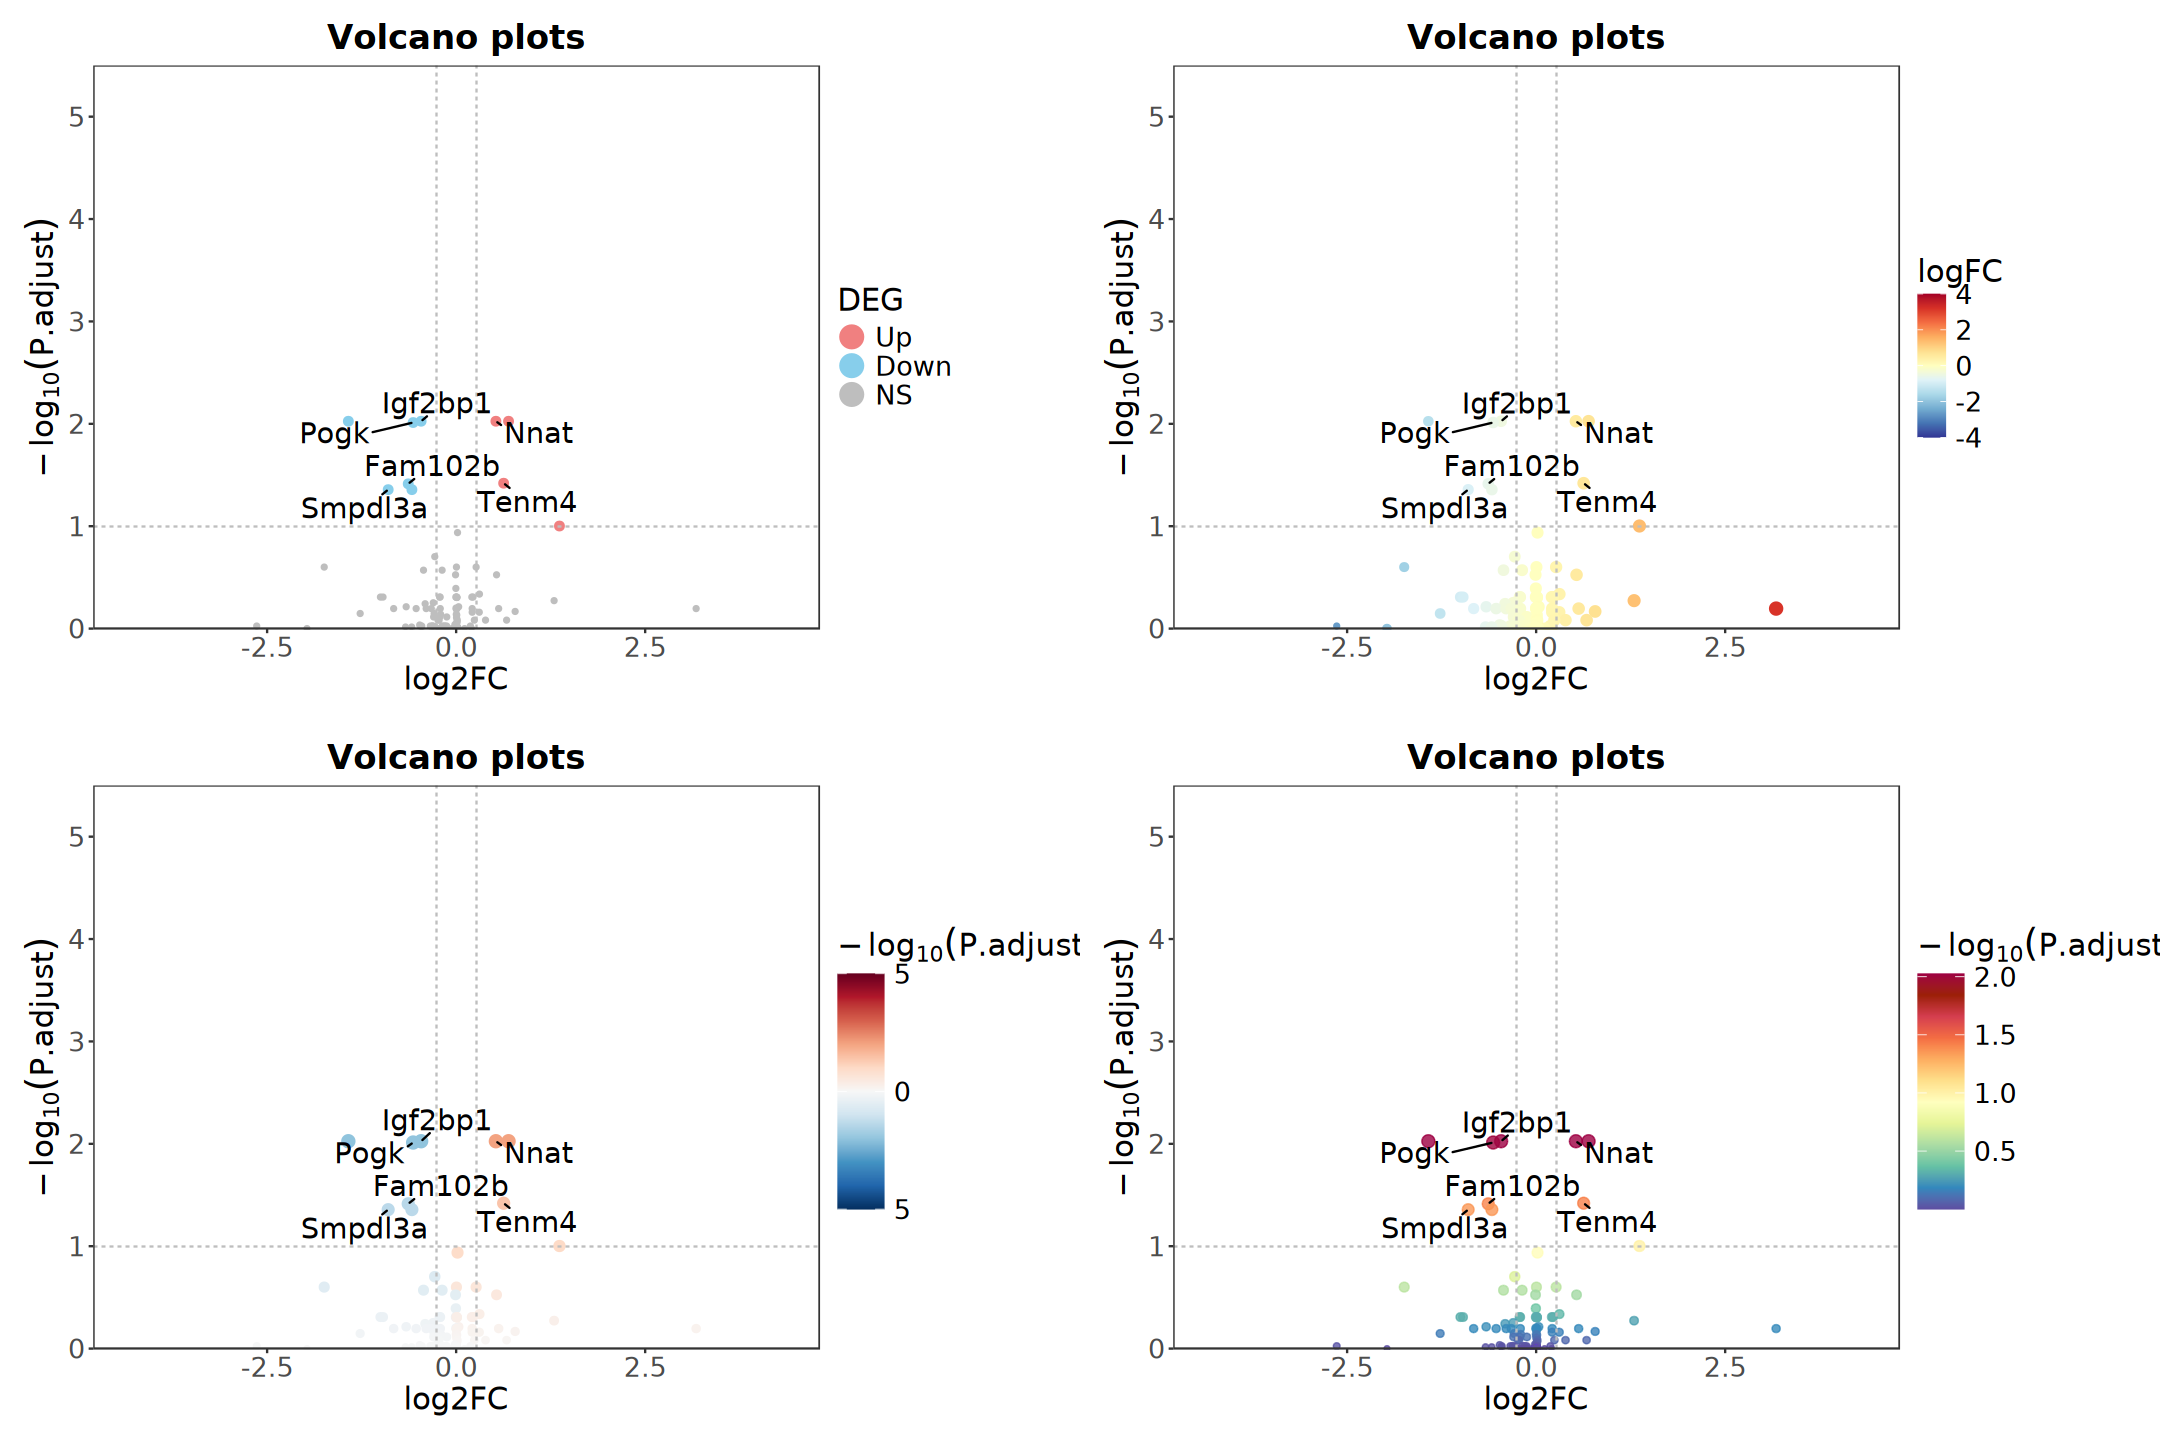

In [105]:
options(repr.plot.width = 18, repr.plot.height = 12)
cowplot::plot_grid(
    p1, p2, p3, p4, nrow = 2, align = "hv", axis = "tblr")

### Scatter Plot

In [106]:
ctrl_samples <- colnames(dds)[dds$Group == "DMSO"]
treat_samples <- colnames(dds)[dds$Group == "EPZ"]

mean_expr <- dds |> 
    counts(normalized = TRUE) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    mutate(
        Ctrl_Mean = rowMeans(across(all_of(ctrl_samples))),
        Treat_Mean = rowMeans(across(all_of(treat_samples)))) |> 
    dplyr::select(gene_id, Ctrl_Mean, Treat_Mean)

In [107]:
plot_df <- degs_result |> 
    rownames_to_column(var = "gene_id") |> 
    inner_join(mean_expr, by = "gene_id") |> 
    mutate(
        log2_Ctrl = log2(Ctrl_Mean + 1),
        log2_Treat = log2(Treat_Mean + 1)) |> 
    drop_na(log2_Ctrl, log2_Treat)

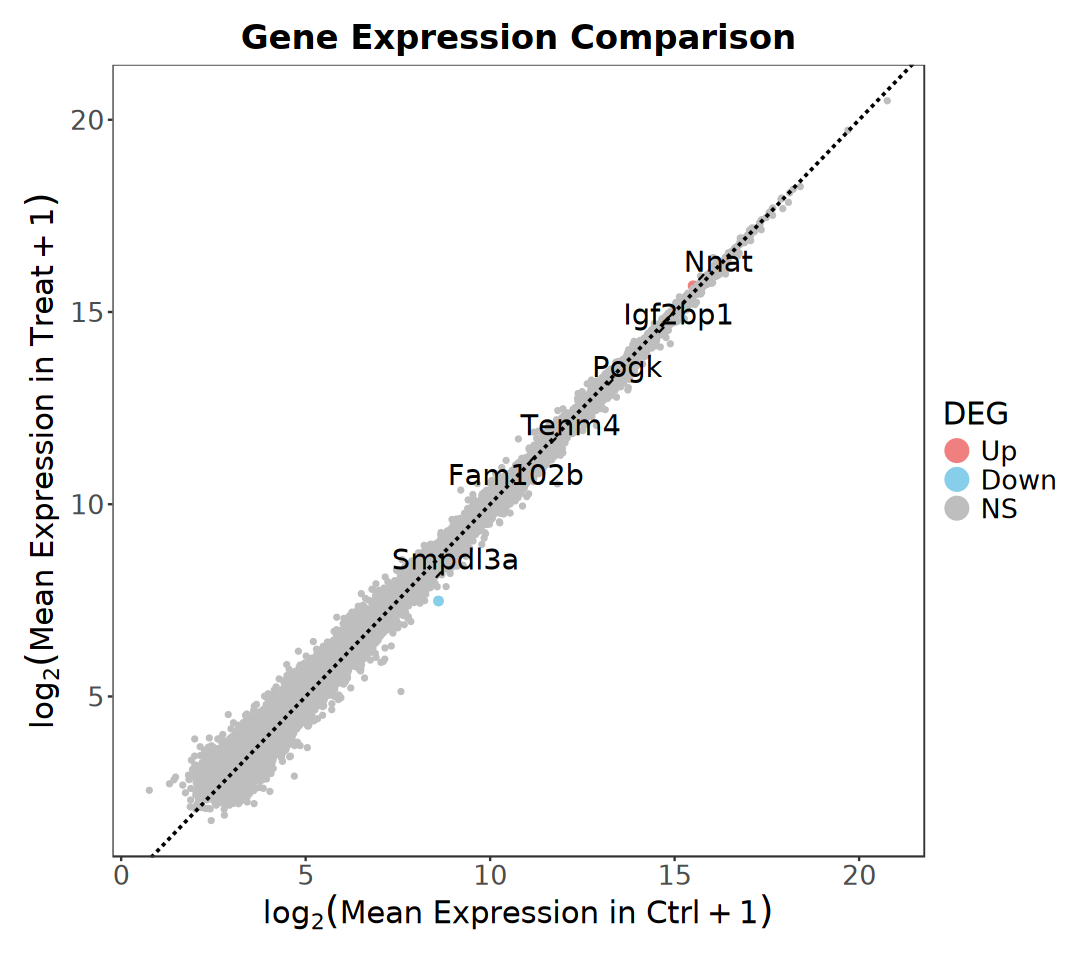

In [108]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = log2_Ctrl, y = log2_Treat)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "black", linewidth = 0.8) +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        box.padding = 0.5, point.padding = 0.3,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    labs(
        title = "Gene Expression Comparison",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = expression(log[2]("Mean Expression in Treat" + 1))) + 
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [109]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [110]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Group, Cell)

In [111]:
cell_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Cell)),
    levels(eSet$Cell))
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Cell = cell_colors, Group = group_colors, 
    Replicate = replicate_colors, DEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

In [112]:
lr <- degs_result |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    arrange(factor(gene_id, levels = rownames(heatmap_dat))) |>
    pull(symbol) |>
    replace_na("")

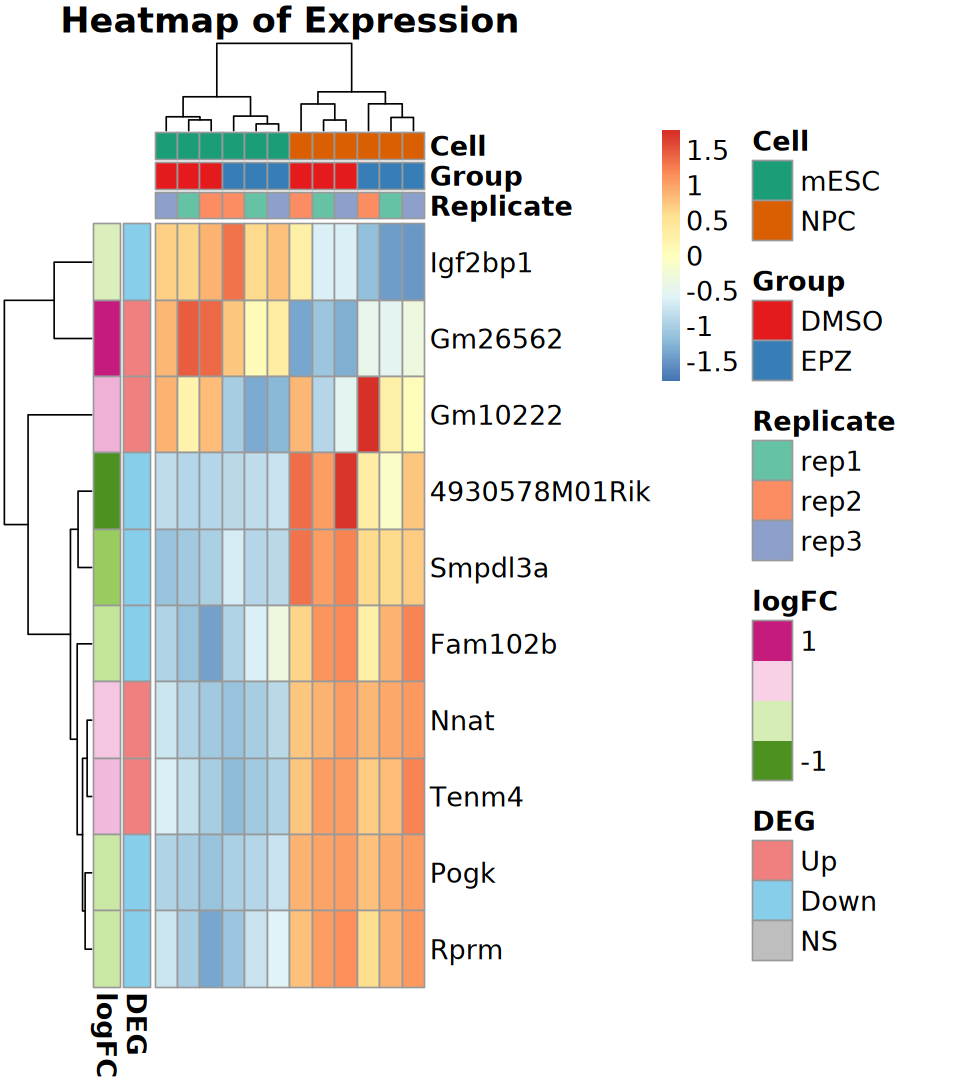

In [113]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, labels_row = lr,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = TRUE)

### ComplexHeatmap

In [114]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [115]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [116]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

cell_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(dds$Cell)),
    levels(dds$Cell))
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [117]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Cell, Group, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Cell = cell_colors,
        Group = group_colors, 
        Replicate = replicate_colors))

In [118]:
ar <- degs_result |> 
    dplyr::select(logFC, DEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [119]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [120]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Cell, Group, Replicate)

In [121]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_cell <- Legend(
    title = "Cell", labels = levels(dds$Cell))
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_cell, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [122]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

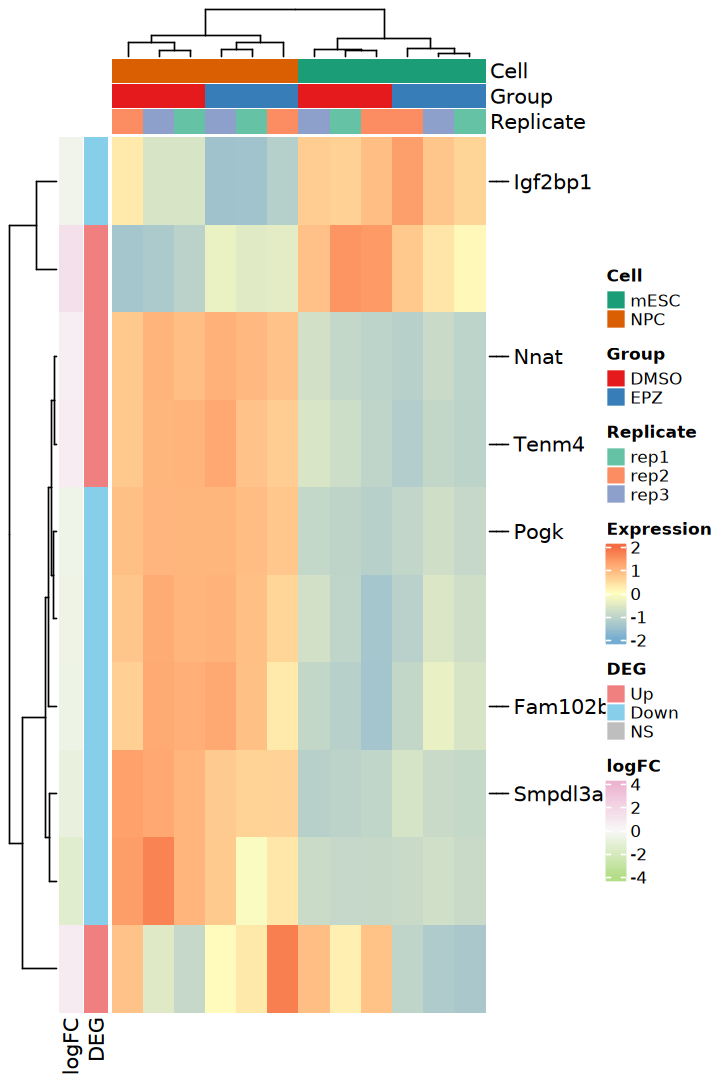

In [123]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)